# 1. Experiment 1 — Dataset Inspection

Dataset: IMDb Movie Reviews từ Hugging Face. Nhãn: 0 = Negative, 1 = Positive. Chỉ sử dụng split có nhãn `train` và `test`; không dùng `unsupervised`.

## 2. Import Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

# Tìm thư mục Lab5 để lưu biểu đồ khi chạy từ các thư mục thường dùng
cwd = Path.cwd()
lab5_candidates = [cwd, cwd / 'Lab5', cwd / 'NLP' / 'Lab5', Path('/home/nguyenducthang/NLP/Lab5')]
LAB_DIR = next((path.resolve() for path in lab5_candidates if (path / 'W5.pdf').is_file()), cwd)
FIGURES_DIR = LAB_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026

/home/nguyenducthang/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Load Dataset

In [2]:
# Tải bộ dữ liệu IMDb; không lấy split unsupervised
imdb = load_dataset('imdb')

train_df = imdb['train'].to_pandas()
test_df = imdb['test'].to_pandas()
train_df['split'] = 'train'
test_df['split'] = 'test'
labeled_df = pd.concat([train_df, test_df], ignore_index=True)

print('Số samples mỗi split:', {'train': len(train_df), 'test': len(test_df)})
print('Tổng samples có nhãn:', len(labeled_df))
print('Tên cột:', list(labeled_df.columns))
print('Ba review đầu của train:')
display(train_df[['text', 'label']].head(3))

Số samples mỗi split: {'train': 25000, 'test': 25000}
Tổng samples có nhãn: 50000
Tên cột: ['text', 'label', 'split']
Ba review đầu của train:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0


## 4. Number of Classes

In [3]:
# Liệt kê các nhãn thực tế và đếm số lớp
label_values = sorted(labeled_df['label'].dropna().unique().tolist())
number_of_classes = len(label_values)
print('Số classes:', number_of_classes)
print('Các giá trị label:', label_values)
print('Chỉ có label 0/1:', set(label_values).issubset({0, 1}))

Số classes: 2
Các giá trị label: [0, 1]
Chỉ có label 0/1: True


## 5. Class Distribution

,split,Class,Count,Percentage
0,test,Negative,12500,50.00%
1,test,Positive,12500,50.00%
2,train,Negative,12500,50.00%
3,train,Positive,12500,50.00%


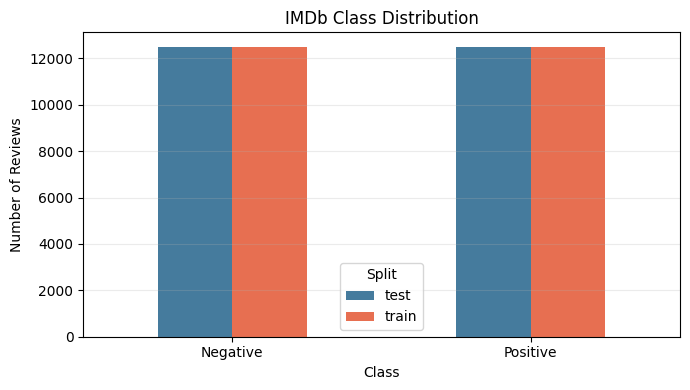

In [4]:
# Đếm review theo lớp và split, sau đó tính phần trăm trong mỗi split
class_names = {0: 'Negative', 1: 'Positive'}
class_counts = (labeled_df.dropna(subset=['label'])
                .groupby(['split', 'label']).size()
                .rename('Count').reset_index())
class_counts['Class'] = class_counts['label'].map(class_names).fillna('Invalid')
class_counts['Percentage'] = class_counts.groupby('split')['Count'].transform(
    lambda values: values / values.sum() * 100
)
class_distribution = class_counts[['split', 'Class', 'Count', 'Percentage']]
display(class_distribution.style.format({'Percentage': '{:.2f}%'}))

# Vẽ biểu đồ cột phân phối nhãn cho train và test
class_plot = class_counts.pivot(index='Class', columns='split', values='Count').fillna(0)
class_plot = class_plot.reindex(['Negative', 'Positive'])
ax = class_plot.plot(kind='bar', figsize=(7, 4), color=['#457b9d', '#e76f51'])
ax.set(title='IMDb Class Distribution', xlabel='Class', ylabel='Number of Reviews')
ax.legend(title='Split')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Document Length Statistics

In [5]:
# Tính độ dài bằng whitespace tokenization: text.split()
labeled_df['sequence_length'] = labeled_df['text'].map(
    lambda text: len(str(text).split()) if pd.notna(text) else 0
)
lengths = labeled_df['sequence_length'].to_numpy()
percentile_values = np.percentile(lengths, [25, 50, 75, 90, 95, 99])
length_statistics = pd.DataFrame({
    'Statistic': ['Minimum', 'Median', 'Mean', 'Maximum', 'Standard deviation',
                  'Percentile 25', 'Percentile 50', 'Percentile 75',
                  'Percentile 90', 'Percentile 95', 'Percentile 99'],
    'Value': [np.min(lengths), np.median(lengths), np.mean(lengths), np.max(lengths),
              np.std(lengths, ddof=1), *percentile_values]
})
display(length_statistics)
print('Standard deviation dùng ddof=1 (sample standard deviation).')

,Statistic,Value
0,Minimum,4.000000
1,Median,173.000000
2,Mean,231.156940
3,Maximum,2470.000000
4,Standard deviation,171.343997
5,Percentile 25,126.000000
6,Percentile 50,173.000000
7,Percentile 75,280.000000
8,Percentile 90,451.000000
9,Percentile 95,590.000000


Standard deviation dùng ddof=1 (sample standard deviation).


## 7. Duplicate Documents

In [6]:
# Đếm các dòng trùng nguyên văn trên toàn bộ dữ liệu có nhãn
duplicate_rows = int(labeled_df['text'].duplicated(keep='first').sum())
duplicate_percentage = duplicate_rows / len(labeled_df) * 100 if len(labeled_df) else 0
print(f'Duplicate rows toàn bộ: {duplicate_rows} ({duplicate_percentage:.4f}%)')

# Kiểm tra lặp bên trong từng split
within_split_rows = {}
for split_name, frame in [('train', train_df), ('test', test_df)]:
    count = int(frame['text'].duplicated(keep='first').sum())
    within_split_rows[split_name] = count
    print(f'Duplicate rows trong {split_name}: {count}')

# Đếm review khác nhau xuất hiện ở cả train và test
train_texts = set(train_df['text'].dropna())
test_texts = set(test_df['text'].dropna())
cross_split_texts = train_texts & test_texts
print('Review khác nhau trùng giữa train/test:', len(cross_split_texts))

# Hiển thị một vài ví dụ nếu có duplicates
duplicate_examples = (labeled_df.dropna(subset=['text'])
                     .groupby('text').filter(lambda group: len(group) > 1)
                     .drop_duplicates(subset=['text']).head(3))
if not duplicate_examples.empty:
    display(duplicate_examples.assign(text=duplicate_examples['text'].str.slice(0, 250))
            [['text', 'label', 'split']])
else:
    print('Không tìm thấy review trùng nguyên văn.')

Duplicate rows toàn bộ: 418 (0.8360%)


Duplicate rows trong train: 96
Duplicate rows trong test: 199
Review khác nhau trùng giữa train/test: 123


,text,label,split
6,Whoever wrote the screenplay for this movie ob...,0,train
7,"When I first saw a glimpse of this movie, I qu...",0,train
167,I am not so much like Love Sick as I image. Fi...,0,train


## 8. Missing Values

In [7]:
# Kiểm tra missing/empty text và missing/invalid labels
missing_text = labeled_df['text'].isna()
empty_text = labeled_df['text'].notna() & labeled_df['text'].astype(str).str.strip().eq('')
missing_label = labeled_df['label'].isna()
invalid_label = labeled_df['label'].notna() & ~labeled_df['label'].isin([0, 1])
missing_summary = pd.DataFrame({
    'Check': ['Missing text', 'Empty/whitespace text', 'Missing label', 'Invalid label'],
    'Count': [missing_text.sum(), empty_text.sum(), missing_label.sum(), invalid_label.sum()]
})
missing_summary['Percentage'] = missing_summary['Count'] / len(labeled_df) * 100
display(missing_summary.style.format({'Percentage': '{:.4f}%'}))

,Check,Count,Percentage
0,Missing text,0,0.0000%
1,Empty/whitespace text,0,0.0000%
2,Missing label,0,0.0000%
3,Invalid label,0,0.0000%


## 9. Sequence Length Histogram

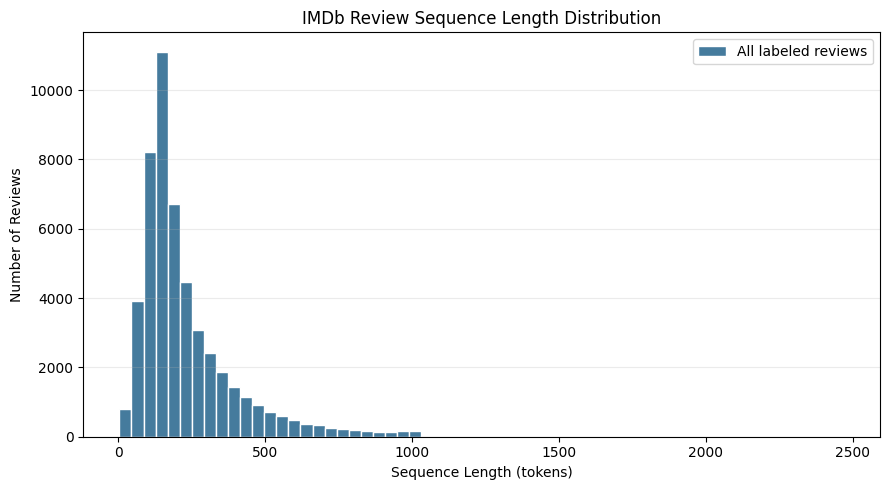

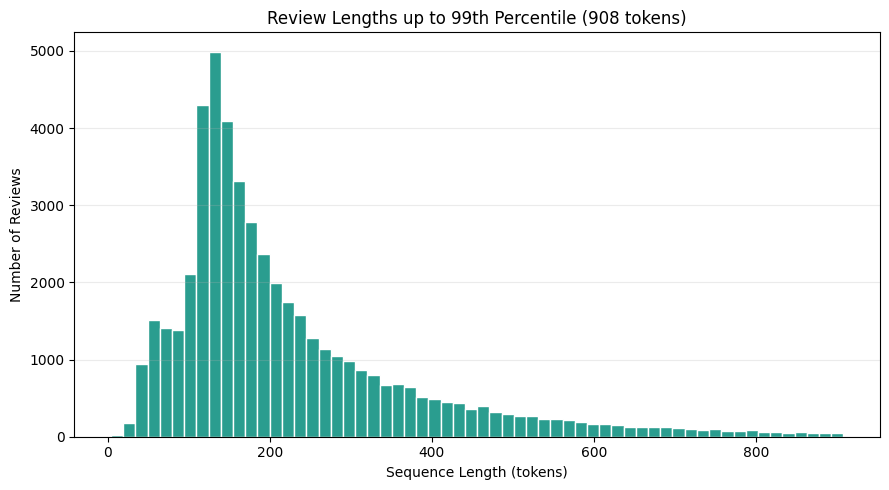

In [8]:
# Vẽ và lưu histogram độ dài review
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(lengths, bins=60, color='#457b9d', edgecolor='white', label='All labeled reviews')
ax.set(title='IMDb Review Sequence Length Distribution',
       xlabel='Sequence Length (tokens)', ylabel='Number of Reviews')
ax.grid(axis='y', alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_histogram.png', dpi=150)
plt.show()

# Biểu đồ phụ giới hạn đến percentile 99 để xem rõ phần chính của phân phối
p99 = np.percentile(lengths, 99)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(lengths[lengths <= p99], bins=60, color='#2a9d8f', edgecolor='white')
ax.set(title=f'Review Lengths up to 99th Percentile ({p99:.0f} tokens)',
       xlabel='Sequence Length (tokens)', ylabel='Number of Reviews')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_histogram_p99.png', dpi=150)
plt.show()

## 10. Max Length Analysis

,Max_Length,Reviews_Fully_Retained_Percent,Tokens_Retained_Percent,Reviews_Truncated_Percent
0,30,0.22%,12.83%,99.78%
1,50,2.42%,21.30%,97.58%
2,100,11.93%,41.18%,88.07%
3,150,39.52%,57.38%,60.48%
4,200,58.59%,68.12%,41.41%
5,300,77.12%,81.38%,22.88%
6,500,91.93%,93.42%,8.07%


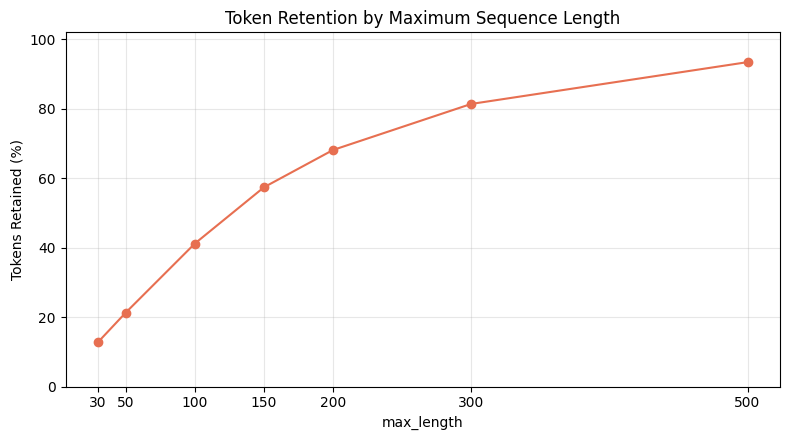

In [9]:
# Ưu tiên độ dài review của train khi phân tích max_length
train_lengths = train_df['text'].map(
    lambda text: len(str(text).split()) if pd.notna(text) else 0
).to_numpy()
max_length_values = [30, 50, 100, 150, 200, 300, 500]
total_train_tokens = train_lengths.sum()
max_length_rows = []
for max_length in max_length_values:
    retained_tokens = np.minimum(train_lengths, max_length).sum()
    fully_retained = np.sum(train_lengths <= max_length)
    truncated = np.sum(train_lengths > max_length)
    max_length_rows.append({
        'Max_Length': max_length,
        'Reviews_Fully_Retained_Percent': fully_retained / len(train_lengths) * 100,
        'Tokens_Retained_Percent': retained_tokens / total_train_tokens * 100,
        'Reviews_Truncated_Percent': truncated / len(train_lengths) * 100
    })
max_length_table = pd.DataFrame(max_length_rows)
display(max_length_table.style.format({
    'Reviews_Fully_Retained_Percent': '{:.2f}%',
    'Tokens_Retained_Percent': '{:.2f}%',
    'Reviews_Truncated_Percent': '{:.2f}%'
}))
max_length_table.to_csv(LAB_DIR / 'max_length_analysis.csv', index=False)

# Vẽ tỷ lệ token được giữ lại theo max_length
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(max_length_table['Max_Length'], max_length_table['Tokens_Retained_Percent'],
        marker='o', color='#e76f51')
ax.set(title='Token Retention by Maximum Sequence Length',
       xlabel='max_length', ylabel='Tokens Retained (%)', xticks=max_length_values)
ax.set_ylim(0, 102)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'max_length_token_retention.png', dpi=150)
plt.show()

## 11. Question & Answer

**Question: Nếu phải chọn max_length, nên chọn dựa trên thông tin nào?**

**Answer (phân tích có AI hỗ trợ, dựa trên output):**

Nên chọn `max_length` bằng cách xem đồng thời phân bố độ dài, phần trăm token giữ lại, tỷ lệ review bị cắt và chi phí huấn luyện/bộ nhớ; không nên chỉ chọn theo một percentile. Corpus có median 173 token, mean 231.16, P90=451 và P95=590. Trong thí nghiệm LSTM, max_length 50/100/200 giữ lần lượt 21.21%/41.03%/68.02% token và cắt 97.69%/88.03%/41.78% review. Test F1 lần lượt là 0.7118/0.6303/0.7691, còn thời gian 22.45/58.49/187.68 giây. Vì kết quả F1 không tăng đều theo độ dài, lựa chọn cần cân nhắc hiệu năng và chi phí trên validation, rồi chỉ báo cáo test sau khi đã chốt cấu hình.

**Student verification:** prediction trước experiment (nếu đã ghi riêng) không được sửa lại; xác nhận xem trade-off này phù hợp với mục tiêu bài và lưu ý các số liệu đến từ một lượt chạy CPU.

# 12. Tokenization và Vocabulary

### Import bổ sung

In [3]:
from collections import Counter
from html import unescape
import re
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# ID đặc biệt được giữ cố định để dùng nhất quán ở các mục sau
PAD_TOKEN, UNK_TOKEN = '<PAD>', '<UNK>'
PAD_ID, UNK_ID = 0, 1

### Task 1 — Tokenization

In [4]:
def tokenize(text):
    # Xử lý text thiếu an toàn, giải mã HTML và bỏ tag HTML cơ bản
    if pd.isna(text):
        return []
    text = unescape(str(text)).lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    # Tách từ và vẫn giữ các từ phủ định như not, no, never
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text)

example_text = 'I really like this movie'
print('Văn bản gốc:', example_text)
print('Tokens:', tokenize(example_text))

Văn bản gốc: I really like this movie
Tokens: ['i', 'really', 'like', 'this', 'movie']


### Task 2 — Build Vocabulary

In [5]:
def build_vocab(train_texts, max_vocab_size=20000, min_freq=2):
    # Hai ID đầu dành riêng cho padding và từ chưa gặp
    if max_vocab_size < 2:
        raise ValueError('max_vocab_size phải ít nhất bằng 2 để chứa PAD và UNK')
    token_counts = Counter()
    for text in train_texts:
        token_counts.update(tokenize(text))

    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    # Giới hạn tổng vocabulary, bao gồm cả hai token đặc biệt
    available_slots = max_vocab_size - len(vocab)
    selected_tokens = [
        token for token, frequency in token_counts.most_common()
        if frequency >= min_freq
    ][:available_slots]
    for token in selected_tokens:
        vocab[token] = len(vocab)
    return vocab, token_counts

# Chỉ dùng split train gốc; không dùng validation/test để xây vocabulary
train_texts = train_df['text'].dropna().astype(str).tolist()
vocab, token_counts = build_vocab(train_texts, max_vocab_size=20000, min_freq=2)
print('Vocabulary size (gồm PAD và UNK):', len(vocab))
print('Một số token và ID:')
display(pd.DataFrame(list(vocab.items())[:12], columns=['Token', 'ID']))

Vocabulary size (gồm PAD và UNK): 20000
Một số token và ID:


,Token,ID
0,<PAD>,0
1,<UNK>,1
2,the,2
3,and,3
4,a,4
5,of,5
6,to,6
7,is,7
8,in,8
9,it,9


### Task 3 — Convert Text to Token IDs

In [13]:
def text_to_ids(text, vocab):
    # Token chưa có trong vocabulary được ánh xạ thành UNK_ID
    return [vocab.get(token, UNK_ID) for token in tokenize(text)]

example_ids = text_to_ids(example_text, vocab)
print('Original text:', example_text)
print('Tokens:', tokenize(example_text))
print('Token IDs lấy từ vocabulary:', example_ids)

Original text: I really like this movie
Tokens: ['i', 'really', 'like', 'this', 'movie']
Token IDs lấy từ vocabulary: [10, 63, 37, 11, 17]


### Task 4 — Padding

In [14]:
def pad_sequence(token_ids, max_length):
    # Hàm nhận sequence đã truncate nếu sequence dài hơn giới hạn
    if max_length < 0:
        raise ValueError('max_length không được âm')
    if len(token_ids) > max_length:
        raise ValueError('Hãy truncate sequence trước khi padding')
    pad_count = max_length - len(token_ids)
    return list(token_ids) + [PAD_ID] * pad_count, pad_count

# Các ID dưới đây là ví dụ giả định để minh họa padding
example_fake_ids = [12, 47, 31, 8, 102]
padded_example, added_pad_count = pad_sequence(example_fake_ids, max_length=8)
print('Input IDs minh họa:', example_fake_ids)
print('IDs sau padding:', padded_example)
print('Số PAD được thêm:', added_pad_count)

Input IDs minh họa: [12, 47, 31, 8, 102]
IDs sau padding: [12, 47, 31, 8, 102, 0, 0, 0]
Số PAD được thêm: 3


### Task 5 — Truncation

In [15]:
def truncate_sequence(token_ids, max_length):
    # Mặc định giữ các token đầu và loại phần vượt giới hạn
    if max_length < 0:
        raise ValueError('max_length không được âm')
    truncated_ids = list(token_ids[:max_length])
    removed_count = max(0, len(token_ids) - max_length)
    return truncated_ids, removed_count

# Dãy ID giả định dùng để minh họa truncation, không phải kết quả dataset
long_fake_ids = list(range(1, 13))
shortened_ids, removed_count = truncate_sequence(long_fake_ids, max_length=8)
print('Sequence trước truncation:', long_fake_ids)
print('Sequence sau truncation:', shortened_ids)
print('Số token bị loại:', removed_count)

Sequence trước truncation: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Sequence sau truncation: [1, 2, 3, 4, 5, 6, 7, 8]
Số token bị loại: 4


### Task 6 — Kết hợp Padding và Truncation

In [16]:
def encode_text(text, vocab, max_length):
    # Thứ tự xử lý: text -> tokens -> IDs -> truncation -> padding
    token_ids = text_to_ids(text, vocab)
    truncated_ids, _ = truncate_sequence(token_ids, max_length)
    actual_length = len(truncated_ids)  # Không tính PAD; bằng 0 nếu câu rỗng
    encoded_ids, _ = pad_sequence(truncated_ids, max_length)
    return encoded_ids, actual_length

max_length_example = 8
encoding_examples = [
    ('short', 'I really like this movie'),
    ('long', 'I really like this movie because the acting was excellent and the story was moving'),
    ('exact length', 'one two three four five six seven eight'),
    ('empty', '')
]
for name, text in encoding_examples:
    encoded_ids, actual_length = encode_text(text, vocab, max_length_example)
    print(f'{name}: text={text!r}')
    print('  token count before:', len(tokenize(text)))
    print('  encoded IDs:', encoded_ids)
    print('  actual_length:', actual_length)
    print('  output length:', len(encoded_ids))

short: text='I really like this movie'
  token count before: 5
  encoded IDs: [10, 63, 37, 11, 17, 0, 0, 0]
  actual_length: 5
  output length: 8
long: text='I really like this movie because the acting was excellent and the story was moving'
  token count before: 15
  encoded IDs: [10, 63, 37, 11, 17, 85, 2, 112]
  actual_length: 8
  output length: 8
exact length: text='one two three four five six seven eight'
  token count before: 8
  encoded IDs: [28, 104, 286, 683, 671, 1443, 1540, 2317]
  actual_length: 8
  output length: 8
empty: text=''
  token count before: 0
  encoded IDs: [0, 0, 0, 0, 0, 0, 0, 0]
  actual_length: 0
  output length: 8


### Task 7 — Embedding

In [17]:
embedding_max_length = 8
embedding_ids, embedding_actual_length = encode_text(example_text, vocab, embedding_max_length)
token_ids_tensor = torch.tensor([embedding_ids], dtype=torch.long)  # Thêm batch dimension

# Embedding đổi ID thành vector dense; padding_idx giữ vector PAD bằng 0 và không cập nhật gradient cho PAD
embedding_layer = nn.Embedding(len(vocab), embedding_dim=50, padding_idx=PAD_ID)
embedding_tensor = embedding_layer(token_ids_tensor)
print('Token IDs tensor shape:', tuple(token_ids_tensor.shape))
print('Embedding tensor shape:', tuple(embedding_tensor.shape))
print('Actual length, không tính PAD:', embedding_actual_length)
print('PAD chỉ là vị trí đệm, không phải thông tin ngôn ngữ.')

Token IDs tensor shape: (1, 8)
Embedding tensor shape: (1, 8, 50)
Actual length, không tính PAD: 5
PAD chỉ là vị trí đệm, không phải thông tin ngôn ngữ.


### Task 8 — Minh họa RNN/LSTM/GRU Input

In [18]:
# Tạo batch gồm một câu ngắn và một câu dài hơn để có padding cuối câu
demo_texts = [
    'I really like this movie',
    'I really like this movie because the acting was excellent'
]
demo_max_length = 8
demo_encoded = [encode_text(text, vocab, demo_max_length) for text in demo_texts]
demo_ids = torch.tensor([item[0] for item in demo_encoded], dtype=torch.long)
demo_lengths = torch.tensor([item[1] for item in demo_encoded], dtype=torch.long)
demo_embeddings = embedding_layer(demo_ids)

# Pack sequence theo độ dài thật để recurrent layer không xử lý PAD như từ ngôn ngữ
packed_embeddings = pack_padded_sequence(
    demo_embeddings, demo_lengths.cpu(), batch_first=True, enforce_sorted=False
)
print('Input token IDs shape:', tuple(demo_ids.shape))
print('Input embeddings shape:', tuple(demo_embeddings.shape))
print('Actual lengths:', demo_lengths.tolist())

for layer_name, recurrent_layer in [
    ('RNN', nn.RNN(input_size=50, hidden_size=16, batch_first=True)),
    ('LSTM', nn.LSTM(input_size=50, hidden_size=16, batch_first=True)),
    ('GRU', nn.GRU(input_size=50, hidden_size=16, batch_first=True))
]:
    packed_output, hidden_state = recurrent_layer(packed_embeddings)
    output, _ = pad_packed_sequence(
        packed_output, batch_first=True, total_length=demo_max_length
)
    print(f'{layer_name} output shape:', tuple(output.shape))
    if layer_name == 'LSTM':
        hidden, cell = hidden_state
        print('  LSTM hidden state shape:', tuple(hidden.shape))
        print('  LSTM cell state shape:', tuple(cell.shape))
    else:
        print('  Hidden state shape:', tuple(hidden_state.shape))

Input token IDs shape: (2, 8)
Input embeddings shape: (2, 8, 50)
Actual lengths: [5, 8]
RNN output shape: (2, 8, 16)
  Hidden state shape: (1, 2, 16)
LSTM output shape: (2, 8, 16)
  LSTM hidden state shape: (1, 2, 16)
  LSTM cell state shape: (1, 2, 16)
GRU output shape: (2, 8, 16)
  Hidden state shape: (1, 2, 16)


### Task 9 — Giải thích Padding và Truncation

#### Padding
Padding bổ sung token đặc biệt PAD vào sequence ngắn để các sequence trong cùng batch có độ dài thống nhất. PAD không mang ý nghĩa ngôn ngữ và cần được xử lý phù hợp trong mô hình.

#### Truncation
Truncation cắt bỏ một phần sequence nếu số token vượt quá max_length. Thao tác này có thể làm mất từ quan trọng, đặc biệt là từ phủ định hoặc từ thể hiện sentiment.

#### Comparison
| Tiêu chí | Padding | Truncation |
|---|---|---|
| Mục đích | Đồng nhất độ dài | Giới hạn độ dài |
| Áp dụng | Sequence ngắn | Sequence dài |
| Thao tác | Thêm PAD | Loại bỏ token |
| Nguy cơ | Xử lý PAD không đúng | Mất thông tin |

## Core Implementation — Simple RNN Cell

### 1. Import SimpleRNNCell

In [19]:
import sys
import numpy as np
import torch
from torch import nn

# Thêm thư mục notebook vào đường dẫn import nếu cần
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
from rnn_cell import SimpleRNNCell

np.random.seed(2026)
torch.manual_seed(2026)

### 2. Initialize Parameters

In [20]:
input_size = 2
hidden_size = 2
cell = SimpleRNNCell(input_size=input_size, hidden_size=hidden_size, seed=2026)

# Gán tham số trong Bài 1 để có thể tự đối chiếu phép tính
cell.W_xh = np.array([[0.5, 0.2], [0.1, 0.4]], dtype=np.float64)
cell.W_hh = np.array([[0.3, 0.1], [0.2, 0.5]], dtype=np.float64)
cell.b_h = np.array([0.0, 0.0], dtype=np.float64)

x_t = np.array([-1.0, 1.0], dtype=np.float64)
h_prev = np.array([0.5, 0.2], dtype=np.float64)
print('W_xh shape:', cell.W_xh.shape)
print('W_hh shape:', cell.W_hh.shape)
print('b_h shape:', cell.b_h.shape)

W_xh shape: (2, 2)
W_hh shape: (2, 2)
b_h shape: (2,)


### 3. Manual Forward Pass

In [21]:
# Tính riêng từng phần của công thức RNN cell
input_contribution = cell.W_xh @ x_t  # Ảnh hưởng của input hiện tại
recurrent_contribution = cell.W_hh @ h_prev  # Ảnh hưởng của hidden state trước
pre_activation = input_contribution + recurrent_contribution + cell.b_h  # Cộng bias
h_t = cell.forward(x_t, h_prev)  # Áp dụng tanh để tạo hidden state mới

print('Input x_t:', x_t)
print('Previous hidden state:', h_prev)
print('W_xh @ x_t:', input_contribution)
print('W_hh @ h_prev:', recurrent_contribution)
print('Pre-activation a_t:', pre_activation)
print('Hidden state h_t:', h_t)

Input x_t: [-1.  1.]
Previous hidden state: [0.5 0.2]
W_xh @ x_t: [-0.3  0.3]
W_hh @ h_prev: [0.17 0.2 ]
Pre-activation a_t: [-0.13  0.5 ]
Hidden state h_t: [-0.12927258  0.46211716]


### 4. Compare with PyTorch RNNCell

In [22]:
# PyTorch chia bias thành bias_ih và bias_hh
torch_cell = nn.RNNCell(input_size=2, hidden_size=2, nonlinearity='tanh').double()
with torch.no_grad():
    torch_cell.weight_ih.copy_(torch.from_numpy(cell.W_xh))
    torch_cell.weight_hh.copy_(torch.from_numpy(cell.W_hh))
    torch_cell.bias_ih.copy_(torch.from_numpy(cell.b_h))
    torch_cell.bias_hh.zero_()

torch_x = torch.from_numpy(x_t)
torch_h_prev = torch.from_numpy(h_prev)
torch_output = torch_cell(torch_x, torch_h_prev).detach().numpy()
custom_output = cell.forward(x_t, h_prev)
max_absolute_difference = float(np.max(np.abs(custom_output - torch_output)))
matches = np.allclose(custom_output, torch_output, atol=1e-8, rtol=0.0)

print('Custom RNN output:', custom_output)
print('PyTorch RNNCell output:', torch_output)
print('Max absolute difference:', max_absolute_difference)
print('Comparison:', 'PASS' if matches else 'FAIL')

Custom RNN output: [-0.12927258  0.46211716]
PyTorch RNNCell output: [-0.12927258  0.46211716]
Max absolute difference: 0.0
Comparison: PASS


### 5. Shape Checking

In [23]:
shape_output = cell.forward(x_t, h_prev)
print('Input shape:', x_t.shape)
print('Previous hidden state shape:', h_prev.shape)
print('Output shape:', shape_output.shape)

# Bắt lỗi shape sai để notebook vẫn chạy tiếp
try:
    cell.forward(np.array([1.0]), h_prev)
except ValueError as error:
    print('Thông báo lỗi shape:', error)

Input shape: (2,)
Previous hidden state shape: (2,)
Output shape: (2,)
Thông báo lỗi shape: x_t phải có shape (2,), nhận được (1,)


### 6. Computation Graph Explanation

Sơ đồ tính toán:

    x_t ------> W_xh -----|
                          + ----> cộng bias ----> tanh ----> h_t
    h_prev ---> W_hh -----|

- x_t: vector đầu vào tại timestep hiện tại.
- W_xh: trọng số xử lý input.
- h_prev: hidden state từ timestep trước.
- W_hh: trọng số xử lý thông tin recurrent.
- b_h: bias được cộng vào tổng.
- tanh: hàm kích hoạt.
- h_t: hidden state mới, kết hợp input hiện tại với thông tin trước đó.

### 7. Additional Tests

In [24]:
# Dùng cùng weights đã gán ở trên để so sánh thêm ba input
rng = np.random.default_rng(2026)
for test_number in range(1, 4):
    random_x = rng.uniform(-1.0, 1.0, size=2).astype(np.float64)
    random_h = rng.uniform(-1.0, 1.0, size=2).astype(np.float64)
    custom_result = cell.forward(random_x, random_h)

    with torch.no_grad():
        torch_result = torch_cell(
            torch.from_numpy(random_x), torch.from_numpy(random_h)
        ).cpu().numpy()

    difference = float(np.max(np.abs(custom_result - torch_result)))
    is_match = np.allclose(custom_result, torch_result, atol=1e-8, rtol=0.0)
    print(f'Test {test_number}: max_abs_diff={difference:.3e} | ' +
          ('PASS' if is_match else 'FAIL'))

Test 1: max_abs_diff=1.388e-17 | PASS
Test 2: max_abs_diff=6.939e-18 | PASS
Test 3: max_abs_diff=0.000e+00 | PASS


### 8. Conclusion — phân tích tham khảo (AI hỗ trợ)

- RNN kết hợp `x_t` và `h_prev` bằng các phép biến đổi tuyến tính, cộng bias rồi đưa tổng qua `tanh`: `h_t = tanh(W_xh x_t + W_hh h_prev + b_h)`.
- `W_xh` biến đổi input ở timestep hiện tại; `W_hh` biến đổi thông tin từ hidden state trước đó.
- `tanh` tạo phi tuyến và đưa giá trị hidden state vào khoảng [-1, 1].
- `h_t` là trạng thái mới, tóm tắt input hiện tại cùng thông tin được truyền từ các timestep trước; đây là biểu diễn hữu hạn nên không đảm bảo giữ mọi chi tiết.
- Test đối chiếu đã PASS: ví dụ được yêu cầu có max absolute difference 0.0; ba kiểm tra thêm có sai số lớn nhất `1.388e-17`, đều dưới tolerance.

**Student verification:** các câu trên là diễn giải kỹ thuật do AI hỗ trợ; đối chiếu lại công thức và output của cell test trước khi nộp.

# 15. Experiment 3 — Baseline: TF-IDF + Logistic Regression vs RNN

Hai mô hình dùng cùng train/validation/test. IMDb test gốc được giữ nguyên làm test; từ IMDb train tách riêng train và validation. Validation dùng chọn checkpoint RNN, còn test chỉ dùng đánh giá cuối. Vocabulary được dựng lại trên train con để không học thông tin từ validation/test. Kết quả Lab4 không được tái sử dụng vì cách chia dữ liệu của nó khác.

## 15.1 Tạo tập train, validation và test dùng chung

Tập `test_df` giữ nguyên split chính thức IMDb. Từ `train_df`, tách 80% để huấn luyện và 20% để validation bằng stratified split, seed 2026. Cách này không bằng split 60/20/20 của Lab4, vì vậy các số liệu Lab4 chỉ được xem là tham khảo riêng, không gộp vào bảng so sánh này.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
import copy
import random
import time

# Cố định seed để các phép chia và khởi tạo có thể lặp lại
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# IMDb train gốc được chia thành train/validation; IMDb test gốc vẫn là test
train_data, val_data = train_test_split(
    train_df[['text', 'label']].copy(),
    test_size=0.20,
    random_state=SEED,
    stratify=train_df['label']
)
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_df[['text', 'label']].copy().reset_index(drop=True)

print('Train:', len(train_data), '| Validation:', len(val_data), '| Test:', len(test_data))
print('Split train/validation/test được dùng giống nhau cho cả hai mô hình.')

# Chỉ dùng train con để dựng lại vocabulary, không dùng vocab của toàn IMDb train
train_texts = train_data['text'].astype(str).tolist()
vocab, token_counts = build_vocab(train_texts, max_vocab_size=20000, min_freq=2)
print('Vocabulary size (gồm PAD và UNK):', len(vocab))
print('PAD_ID:', PAD_ID, '| UNK_ID:', UNK_ID)

Train: 20000 | Validation: 5000 | Test: 25000
Split train/validation/test được dùng giống nhau cho cả hai mô hình.


Vocabulary size (gồm PAD và UNK): 20000
PAD_ID: 0 | UNK_ID: 1


## 15.2 Baseline — TF-IDF Unigram + Logistic Regression

Vectorizer chỉ fit trên train. Thời gian được đo cho `fit_transform` của TF-IDF trên train và huấn luyện Logistic Regression; transform validation/test không được tính vào training time.

In [26]:
# Tạo vectorizer unigram và chỉ học vocabulary/IDF từ train
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    lowercase=True
)
y_train = train_data['label'].to_numpy(dtype=np.int64)
y_val = val_data['label'].to_numpy(dtype=np.int64)
y_test = test_data['label'].to_numpy(dtype=np.int64)

tfidf_start = time.perf_counter()
X_train_tfidf = tfidf_vectorizer.fit_transform(train_data['text'].astype(str))
tfidf_lr_model = LogisticRegression(max_iter=1000, random_state=SEED)
tfidf_lr_model.fit(X_train_tfidf, y_train)
tfidf_training_time = time.perf_counter() - tfidf_start

# Validation/test chỉ được biến đổi bằng vectorizer đã fit
X_val_tfidf = tfidf_vectorizer.transform(val_data['text'].astype(str))
X_test_tfidf = tfidf_vectorizer.transform(test_data['text'].astype(str))
tfidf_test_pred = tfidf_lr_model.predict(X_test_tfidf)

def classification_metrics(y_true, y_pred):
    # Tính bốn metric nhị phân với lớp positive là 1
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='binary', pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='binary', pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, average='binary', pos_label=1, zero_division=0)
    }

tfidf_test_metrics = classification_metrics(y_test, tfidf_test_pred)
print('TF-IDF vocabulary:', len(tfidf_vectorizer.vocabulary_))
print(f'TF-IDF + Logistic Regression training time: {tfidf_training_time:.2f} seconds')
display(pd.DataFrame([{'Model': 'Logistic Regression', **tfidf_test_metrics}]).style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'
}))

TF-IDF vocabulary: 10000
TF-IDF + Logistic Regression training time: 2.20 seconds


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8817,0.8797,0.8843,0.8820


## 15.3 Embedding + Simple RNN + Linear Classifier

Mỗi review được tokenize bằng hàm ở Mục 12, mã hóa bằng vocabulary train-only, cắt ở `max_length=100` và padding bằng `PAD_ID`. Sequence length thật được truyền vào `pack_padded_sequence`, nên PAD không tham gia hidden state cuối.

In [27]:
MAX_LENGTH = 100
EMBEDDING_DIM = 50
HIDDEN_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 0.001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def encode_for_rnn(text, vocabulary, max_length):
    # Mã hóa bằng tokenizer/vocabulary đã xây từ train và giữ độ dài thật
    token_ids = text_to_ids(text, vocabulary)[:max_length]
    if not token_ids:
        token_ids = [UNK_ID]  # pack_padded_sequence cần độ dài ít nhất là 1
    actual_length = len(token_ids)
    padded_ids = token_ids + [PAD_ID] * (max_length - actual_length)
    return padded_ids, actual_length

def make_rnn_loader(frame, vocabulary, max_length, batch_size, shuffle=False):
    # Chuyển reviews thành tensor IDs, độ dài và nhãn
    encoded = [encode_for_rnn(text, vocabulary, max_length) for text in frame['text'].astype(str)]
    input_ids = torch.tensor([item[0] for item in encoded], dtype=torch.long)
    lengths = torch.tensor([item[1] for item in encoded], dtype=torch.long)
    labels = torch.tensor(frame['label'].to_numpy(), dtype=torch.float32)
    dataset = TensorDataset(input_ids, lengths, labels)
    loader_generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=loader_generator)

train_loader = make_rnn_loader(train_data, vocab, MAX_LENGTH, BATCH_SIZE, shuffle=True)
val_loader = make_rnn_loader(val_data, vocab, MAX_LENGTH, BATCH_SIZE)
test_loader = make_rnn_loader(test_data, vocab, MAX_LENGTH, BATCH_SIZE)

class RNNSentimentClassifier(nn.Module):
    def __init__(self, vocabulary_size, embedding_dim, hidden_size, padding_id):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=padding_id)
        self.rnn = nn.RNN(embedding_dim, hidden_size, batch_first=True)
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, input_ids, lengths):
        # Embed tokens rồi pack để RNN bỏ qua các vị trí PAD
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)
        final_hidden = hidden[-1]
        logits = self.classifier(final_hidden).squeeze(1)
        return logits, final_hidden

rnn_config = {
    'embedding_dim': EMBEDDING_DIM, 'hidden_size': HIDDEN_SIZE,
    'batch_size': BATCH_SIZE, 'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE, 'max_length': MAX_LENGTH, 'seed': SEED
}
torch.manual_seed(SEED)
rnn_model = RNNSentimentClassifier(len(vocab), EMBEDDING_DIM, HIDDEN_SIZE, PAD_ID).to(DEVICE)
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=LEARNING_RATE)
print('Device:', DEVICE)
print('Vocabulary size:', len(vocab), '| Parameters:', sum(p.numel() for p in rnn_model.parameters()))
print('RNN configuration:', rnn_config)

Device: cpu
Vocabulary size: 20000 | Parameters: 1007489
RNN configuration: {'embedding_dim': 50, 'hidden_size': 64, 'batch_size': 64, 'epochs': 3, 'learning_rate': 0.001, 'max_length': 100, 'seed': 2026}


### Huấn luyện và chọn checkpoint theo Validation F1

Test không được dùng trong training hoặc chọn checkpoint. Mô hình tốt nhất trên validation được khôi phục trước khi đánh giá test.

In [28]:
def evaluate_rnn(model, data_loader, device):
    # Chạy dự đoán không tính gradient và gom logits/nhãn
    model.eval()
    all_logits, all_labels = [], []
    total_loss = 0.0
    loss_fn = nn.BCEWithLogitsLoss()
    with torch.no_grad():
        for input_ids, lengths, labels in data_loader:
            input_ids, lengths = input_ids.to(device), lengths.to(device)
            labels = labels.to(device)
            model_output = model(input_ids, lengths)
            # Mục 15 trả về (logits, hidden), các model ở Mục 19 trả logits trực tiếp
            logits = model_output[0] if isinstance(model_output, tuple) else model_output
            total_loss += loss_fn(logits, labels).item() * len(labels)
            all_logits.extend(logits.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())
    probabilities = torch.sigmoid(torch.tensor(all_logits)).numpy()
    predictions = (probabilities >= 0.5).astype(np.int64)
    metrics = classification_metrics(np.asarray(all_labels, dtype=np.int64), predictions)
    metrics['Loss'] = total_loss / len(data_loader.dataset)
    return metrics, np.asarray(all_labels, dtype=np.int64), predictions, probabilities, np.asarray(all_logits)

def train_rnn(model, train_loader, validation_loader, config):
    # Huấn luyện theo epoch, chọn checkpoint theo F1 trên validation
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    best_f1, best_state, best_epoch = -1.0, None, 0
    start_time = time.perf_counter()

    for epoch in range(1, config['epochs'] + 1):
        model.train()
        total_train_loss = 0.0
        for input_ids, lengths, labels in train_loader:
            input_ids, lengths = input_ids.to(DEVICE), lengths.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad()
            logits, _ = model(input_ids, lengths)
            loss = loss_fn(logits, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(labels)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_metrics, _, _, _, _ = evaluate_rnn(model, validation_loader, DEVICE)
        history.append({
            'Epoch': epoch, 'Train Loss': train_loss,
            'Validation Loss': val_metrics['Loss'], 'Validation F1': val_metrics['F1']
        })
        print(f"Epoch {epoch}/{config['epochs']} | train_loss={train_loss:.4f} | "
              f"val_loss={val_metrics['Loss']:.4f} | val_f1={val_metrics['F1']:.4f}")
        if val_metrics['F1'] > best_f1:
            best_f1, best_epoch = val_metrics['F1'], epoch
            best_state = copy.deepcopy(model.state_dict())

    training_time = time.perf_counter() - start_time
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), training_time, best_epoch

rnn_model, rnn_history, rnn_training_time, best_epoch = train_rnn(
    rnn_model, train_loader, val_loader, rnn_config
)
print(f'RNN training time: {rnn_training_time:.2f} seconds')
print('Best checkpoint epoch (Validation F1):', best_epoch)
display(rnn_history)

Epoch 1/3 | train_loss=0.6952 | val_loss=0.6929 | val_f1=0.5968


Epoch 2/3 | train_loss=0.6795 | val_loss=0.6905 | val_f1=0.5186


Epoch 3/3 | train_loss=0.6571 | val_loss=0.6838 | val_f1=0.5883
RNN training time: 19.18 seconds
Best checkpoint epoch (Validation F1): 1


,Epoch,Train Loss,Validation Loss,Validation F1
0,1,0.695202,0.692863,0.596821
1,2,0.679465,0.690469,0.518595
2,3,0.657072,0.683847,0.588303


## 15.4 Đánh giá trên Test và bảng so sánh

Sau khi đã chọn checkpoint bằng validation, mỗi mô hình được đánh giá đúng một lần trên cùng IMDb test split.

In [29]:
rnn_test_metrics, _, rnn_test_pred, rnn_test_prob, _ = evaluate_rnn(
    rnn_model, test_loader, DEVICE
)

comparison_table = pd.DataFrame([
    {
        'Model': 'Logistic Regression', 'Representation': 'TF-IDF unigram',
        **tfidf_test_metrics, 'Training time (s)': tfidf_training_time
    },
    {
        'Model': 'Simple RNN', 'Representation': 'Embedding',
        **rnn_test_metrics, 'Training time (s)': rnn_training_time
    }
])
display(comparison_table.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'F1': '{:.4f}', 'Training time (s)': '{:.2f}'
}))

# Lưu đúng các kết quả vừa tính, không ghi số liệu dựng sẵn
BASELINE_RESULTS_DIR = LAB_DIR / 'results'
BASELINE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
baseline_results_path = BASELINE_RESULTS_DIR / 'baseline_comparison.csv'
comparison_table.to_csv(baseline_results_path, index=False)
print('Đã lưu bảng kết quả tại:', baseline_results_path)

,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s),Loss
0,Logistic Regression,TF-IDF unigram,0.8817,0.8797,0.8843,0.8820,2.20,nan
1,Simple RNN,Embedding,0.5311,0.5230,0.7082,0.6016,19.18,0.691256


Đã lưu bảng kết quả tại: /home/nguyenducthang/NLP/Lab5/results/baseline_comparison.csv


## 15.5 Thí nghiệm độ nhạy với thứ tự từ

Các câu trong mỗi cặp giữ nguyên token nhưng thay đổi thứ tự. TF-IDF unigram chỉ dựa vào tần suất từ; RNN nhận sequence theo thứ tự. Đây là phép kiểm tra độ nhạy của biểu diễn, không phải nhãn đánh giá câu tự nhiên hay bằng chứng mô hình hiểu ngữ nghĩa.

In [30]:
sequence_pairs = {
    'Agent order': ('dog bites man', 'man bites dog'),
    'Negation order': ('the movie is not good', 'the movie is good not')
}

def predict_rnn_text(text):
    # Trả về logit, xác suất, nhãn dự đoán và hidden state của một câu
    encoded_ids, actual_length = encode_for_rnn(text, vocab, MAX_LENGTH)
    ids_tensor = torch.tensor([encoded_ids], dtype=torch.long, device=DEVICE)
    lengths_tensor = torch.tensor([actual_length], dtype=torch.long, device=DEVICE)
    rnn_model.eval()
    with torch.no_grad():
        logits, hidden = rnn_model(ids_tensor, lengths_tensor)
        probability = torch.sigmoid(logits).item()
    return {
        'logit': float(logits.item()), 'probability': probability,
        'prediction': int(probability >= 0.5),
        'hidden': hidden.squeeze(0).cpu().numpy()
    }

order_rows = []
for pair_name, (sentence_a, sentence_b) in sequence_pairs.items():
    # Vector unigram của hai câu được so trực tiếp bằng số khác nhau trong sparse matrix
    pair_tfidf = tfidf_vectorizer.transform([sentence_a, sentence_b])
    tfidf_vectors_equal = (pair_tfidf[0] != pair_tfidf[1]).nnz == 0
    result_a = predict_rnn_text(sentence_a)
    result_b = predict_rnn_text(sentence_b)
    order_rows.append({
        'Pair': pair_name, 'Sentence A': sentence_a, 'Sentence B': sentence_b,
        'TF-IDF unigram vectors equal': tfidf_vectors_equal,
        'A logit': result_a['logit'], 'A predicted class': result_a['prediction'],
        'A positive probability': result_a['probability'],
        'B logit': result_b['logit'], 'B predicted class': result_b['prediction'],
        'B positive probability': result_b['probability'],
        'Absolute probability difference': abs(result_a['probability'] - result_b['probability']),
        'Final hidden Euclidean distance': float(np.linalg.norm(result_a['hidden'] - result_b['hidden']))
    })

sequence_order_results = pd.DataFrame(order_rows)
display(sequence_order_results.style.format({
    'A logit': '{:.4f}', 'B logit': '{:.4f}',
    'A positive probability': '{:.4f}', 'B positive probability': '{:.4f}',
    'Absolute probability difference': '{:.4f}',
    'Final hidden Euclidean distance': '{:.4f}'
}))

,Pair,Sentence A,Sentence B,TF-IDF unigram vectors equal,A logit,A predicted class,A positive probability,B logit,B predicted class,B positive probability,Absolute probability difference,Final hidden Euclidean distance
0,Agent order,dog bites man,man bites dog,True,-0.2201,0,0.4452,-0.3908,0,0.4035,0.0417,3.8108
1,Negation order,the movie is not good,the movie is good not,True,0.2338,1,0.5582,0.2871,1,0.5713,0.0131,4.3253


## 15.6 Biểu đồ

Biểu đồ được tạo và lưu khi bạn tự chạy các cell này.

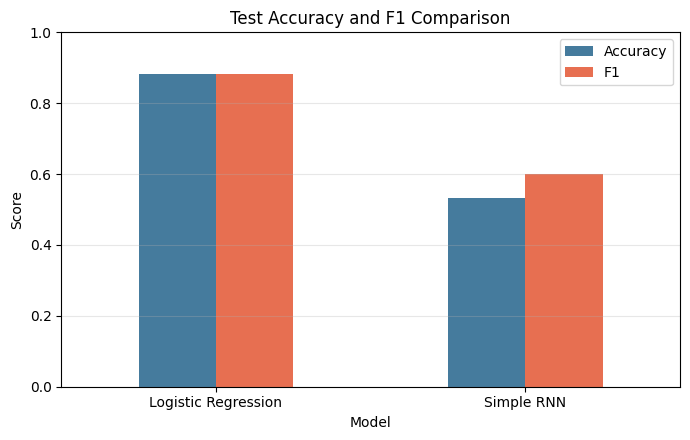

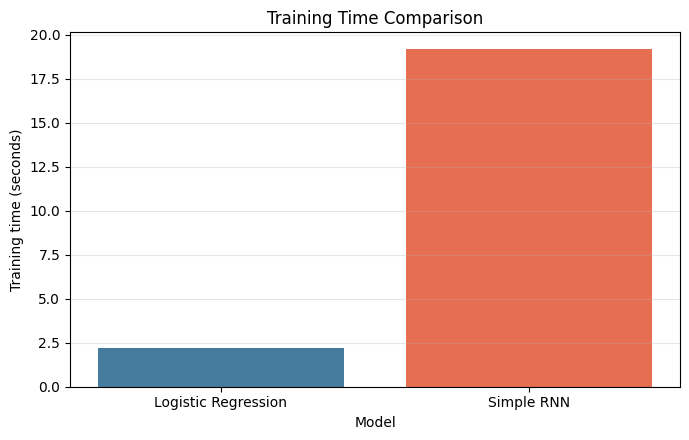

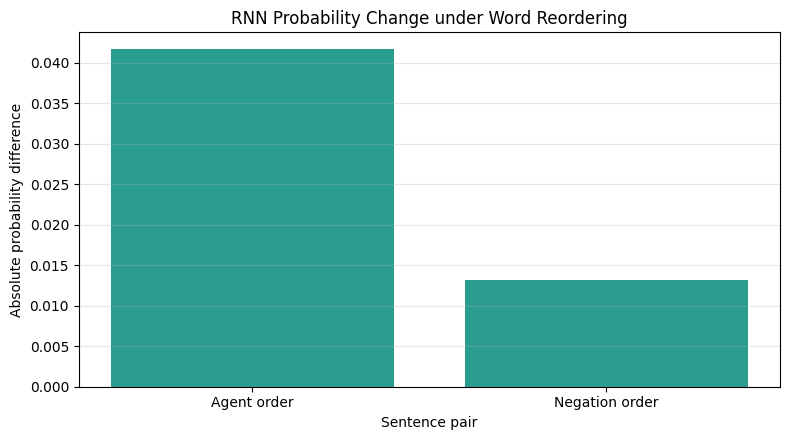

Các hình đã lưu trong: /home/nguyenducthang/NLP/Lab5/figures


In [31]:
# So sánh Accuracy và F1 của hai mô hình
fig, ax = plt.subplots(figsize=(7, 4.5))
comparison_table.set_index('Model')[['Accuracy', 'F1']].plot(kind='bar', ax=ax, color=['#457b9d', '#e76f51'])
ax.set(title='Test Accuracy and F1 Comparison', xlabel='Model', ylabel='Score', ylim=(0, 1))
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'baseline_accuracy_f1.png', dpi=150)
plt.show()

# So sánh thời gian huấn luyện theo phạm vi được ghi ở phần mô tả
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(comparison_table['Model'], comparison_table['Training time (s)'], color=['#457b9d', '#e76f51'])
ax.set(title='Training Time Comparison', xlabel='Model', ylabel='Training time (seconds)')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'baseline_training_time.png', dpi=150)
plt.show()

# Vẽ chênh lệch xác suất dương của các cặp câu đảo thứ tự
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(sequence_order_results['Pair'], sequence_order_results['Absolute probability difference'], color='#2a9d8f')
ax.set(title='RNN Probability Change under Word Reordering', xlabel='Sentence pair', ylabel='Absolute probability difference')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_order_probability_difference.png', dpi=150)
plt.show()
print('Các hình đã lưu trong:', FIGURES_DIR)

## 15.7 Câu hỏi phân tích — phân tích tham khảo (AI hỗ trợ)

### Question và câu trả lời dựa trên evidence
Có. Trong các phép thử này, RNN tạo đầu ra phụ thuộc thứ tự chuỗi, trong khi TF-IDF unigram không phân biệt hai câu có cùng multiset token. Với `dog bites man` / `man bites dog`, vector TF-IDF bằng nhau; P(positive) của RNN là 0.4452/0.4035 (chênh 0.0417), khoảng cách hidden state cuối là 3.8108. Với `the movie is not good` / `the movie is good not`, TF-IDF cũng bằng nhau; P(positive) là 0.5582/0.5713 (chênh 0.0131), hidden-state distance 4.3253.

Các số liệu cho thấy độ nhạy với thứ tự và biểu diễn nội bộ khác nhau; chúng không chứng minh rằng RNN hiểu đúng ngữ nghĩa, vì hai phép thử nhỏ và cả hai câu trong cặp đều nhận cùng nhãn dự đoán. Baseline TF-IDF đạt Accuracy/F1 0.8817/0.8820, còn RNN đạt 0.5311/0.6016 trên test của notebook. TF-IDF training time 2.20 giây được đo cùng fit vectorizer, còn RNN 19.18 giây đo huấn luyện; do đó thời gian chưa phải hoàn toàn cùng phạm vi.

**Student verification:** xác nhận lại đúng câu và số liệu ở output; khi so sánh, nhắc rõ split notebook là 20k/5k/25k và thời gian TF-IDF bao gồm fit vectorizer.

# 19. Experiment 4 — RNN vs LSTM vs GRU

So sánh ba recurrent architecture trên cùng train/validation/test, vocabulary, tokenizer và cách mã hóa của Experiment 3. Chỉ thay loại recurrent layer. Test chỉ được dùng sau khi đã chọn checkpoint theo Validation F1.

## 19.1 Cấu hình thực nghiệm chung

Các tham số được gom trong một cấu hình. Data split, vocabulary, tokenizer và các DataLoader được lấy từ Experiment 3; mỗi model nhận một train loader mới với cùng seed để thứ tự batch bắt đầu giống nhau.

In [8]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 19.2 Xây dựng model và đếm parameters

Embedding biến token IDs thành vector dày. Packed sequence bỏ qua PAD. Hidden state cuối được đưa vào linear classifier để tạo một logit; sigmoid không đặt trong model vì loss là BCEWithLogitsLoss.

In [9]:
class RecurrentSentimentClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, model_type, num_layers=1, dropout=0.0):
        super().__init__()
        model_type = model_type.upper()
        if model_type not in {'RNN', 'LSTM', 'GRU'}:
            raise ValueError('model_type phải là RNN, LSTM hoặc GRU')

        # Embedding ánh xạ mỗi token ID thành vector học được
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        recurrent_classes = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}
        self.recurrent = recurrent_classes[model_type](
            input_size=embedding_dim, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True, dropout=dropout
        )
        self.classifier = nn.Linear(hidden_size, 1)
        self.model_type = model_type

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        # Packed sequence ngăn PAD bị tính như token thật trong recurrent state
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, recurrent_state = self.recurrent(packed)
        # LSTM trả về (h_n, c_n); RNN/GRU chỉ trả h_n
        hidden_state = recurrent_state[0] if self.model_type == 'LSTM' else recurrent_state
        final_hidden = hidden_state[-1]
        # Linear đổi hidden state thành logit cho phân loại nhị phân
        logits = self.classifier(final_hidden).squeeze(1)
        return logits

def count_parameters(model):
    # Chỉ đếm các tham số có thể được cập nhật khi huấn luyện
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

## 19.3 Huấn luyện và validation

Mỗi kiến trúc được khởi tạo độc lập với cùng seed và huấn luyện bằng cùng Adam, BCEWithLogitsLoss, batch size, learning rate và số epoch. Checkpoint tốt nhất được chọn theo Validation F1.

In [34]:
def evaluate_model(model, data_loader):
    # Dùng hàm evaluation đã có ở Experiment 3 và chỉ trả về các metrics
    metrics, _, _, _, _ = evaluate_rnn(model, data_loader, DEVICE)
    return {name: metrics[name] for name in ['Accuracy', 'Precision', 'Recall', 'F1']}

def train_model(model, train_loader, val_loader, config):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    loss_function = nn.BCEWithLogitsLoss()
    history = []
    best_f1, best_epoch, best_state = -1.0, 0, None
    epochs_trained = 0
    start_time = time.perf_counter()

    for epoch in range(1, config['epochs'] + 1):
        model.train()
        total_train_loss = 0.0
        for input_ids, lengths, labels in train_loader:
            input_ids, lengths = input_ids.to(DEVICE), lengths.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad()
            logits = model(input_ids, lengths)
            loss = loss_function(logits, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(labels)

        epochs_trained = epoch
        train_loss = total_train_loss / len(train_loader.dataset)
        val_details, _, _, _, _ = evaluate_rnn(model, val_loader, DEVICE)
        history.append({
            'Epoch': epoch, 'Train Loss': train_loss,
            'Validation Loss': val_details['Loss'], 'Validation F1': val_details['F1']
        })
        print(f"{model.model_type} | epoch {epoch}/{config['epochs']} | "
              f"train_loss={train_loss:.4f} | val_loss={val_details['Loss']:.4f} | "
              f"val_f1={val_details['F1']:.4f}")
        if val_details['F1'] > best_f1:
            best_f1, best_epoch = val_details['F1'], epoch
            best_state = copy.deepcopy(model.state_dict())

    training_time = time.perf_counter() - start_time
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), training_time, best_epoch, epochs_trained

## 19.4 Huấn luyện ba model và đánh giá Test

Mỗi model được tạo mới. Validation dùng chọn checkpoint; test chỉ được chấm sau khi model đã khôi phục checkpoint tốt nhất.

In [35]:
exp4_models = {}
exp4_histories = {}
exp4_rows = []

for model_type in EXP4_MODEL_TYPES:
    # Đặt lại seed trước mỗi lần khởi tạo để phép so sánh dễ tái lập
    random.seed(EXP4_CONFIG['seed'])
    np.random.seed(EXP4_CONFIG['seed'])
    torch.manual_seed(EXP4_CONFIG['seed'])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(EXP4_CONFIG['seed'])

    model = RecurrentSentimentClassifier(
        vocab_size=len(vocab),
        embedding_dim=EXP4_CONFIG['embedding_dim'],
        hidden_size=EXP4_CONFIG['hidden_size'],
        model_type=model_type,
        num_layers=EXP4_CONFIG['num_layers'],
        dropout=EXP4_CONFIG['dropout']
    ).to(DEVICE)
    parameter_count = count_parameters(model)

    # Tạo lại loader từ cùng dữ liệu với cùng seed để mỗi model có batch order tái lập
    model_train_loader = make_rnn_loader(
        train_data, vocab, EXP4_CONFIG['max_length'],
        EXP4_CONFIG['batch_size'], shuffle=True
    )
    model, history, training_time, best_epoch, epochs_trained = train_model(
        model, model_train_loader, val_loader, EXP4_CONFIG
    )

    # Test được sử dụng duy nhất sau khi checkpoint đã được chọn trên validation
    test_metrics = evaluate_model(model, test_loader)
    exp4_models[model_type] = model
    exp4_histories[model_type] = history
    exp4_rows.append({
        'Model': model_type, 'Parameters': parameter_count,
        'Training time (s)': training_time, 'Epochs trained': epochs_trained,
        'Best epoch (Validation F1)': best_epoch, **test_metrics
    })

    history.to_csv(EXP4_RESULTS_DIR / f'rnn_lstm_gru_{model_type.lower()}_history.csv', index=False)
    torch.save({
        'model_type': model_type, 'state_dict': model.state_dict(),
        'config': EXP4_CONFIG, 'vocab_size': len(vocab)
    }, EXP4_CHECKPOINT_DIR / f'{model_type.lower()}_best.pt')

exp4_results = pd.DataFrame(exp4_rows)
display(exp4_results.style.format({
    'Training time (s)': '{:.2f}',
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'
}))
exp4_csv_path = EXP4_RESULTS_DIR / 'rnn_lstm_gru_comparison.csv'
exp4_results.to_csv(exp4_csv_path, index=False)

# Lưu cấu hình để ghi lại chính xác điều kiện chạy
import json
with open(EXP4_RESULTS_DIR / 'rnn_lstm_gru_config.json', 'w', encoding='utf-8') as file:
    json.dump({**EXP4_CONFIG, 'device': str(DEVICE), 'vocabulary_size': len(vocab)}, file, indent=2)
print('Comparison CSV:', exp4_csv_path)
print('History CSVs and configuration:', EXP4_RESULTS_DIR)
print('Checkpoints:', EXP4_CHECKPOINT_DIR)

RNN | epoch 1/3 | train_loss=0.6952 | val_loss=0.6929 | val_f1=0.5968


RNN | epoch 2/3 | train_loss=0.6795 | val_loss=0.6905 | val_f1=0.5186


RNN | epoch 3/3 | train_loss=0.6571 | val_loss=0.6838 | val_f1=0.5883


LSTM | epoch 1/3 | train_loss=0.6944 | val_loss=0.6928 | val_f1=0.6027


LSTM | epoch 2/3 | train_loss=0.6878 | val_loss=0.6627 | val_f1=0.6370


...

GRU | epoch 1/3 | train_loss=0.6809 | val_loss=0.6853 | val_f1=0.6393


GRU | epoch 2/3 | train_loss=0.6163 | val_loss=0.5731 | val_f1=0.7329


GRU | epoch 3/3 | train_loss=0.5015 | val_loss=0.4923 | val_f1=0.7953


,Model,Parameters,Training time (s),Epochs trained,Best epoch (Validation F1),Accuracy,Precision,Recall,F1
0,RNN,1007489,19.53,3,1,0.5311,0.5230,0.7082,0.6016
1,LSTM,1029761,60.35,3,2,0.6112,0.6007,0.6630,0.6303
2,GRU,1022337,46.16,3,3,0.7567,0.7221,0.8346,0.7743


Comparison CSV: /home/nguyenducthang/NLP/Lab5/results/rnn_lstm_gru_comparison.csv
History CSVs and configuration: /home/nguyenducthang/NLP/Lab5/results
Checkpoints: /home/nguyenducthang/NLP/Lab5/models/rnn_lstm_gru


## 19.5 Visualization

Các biểu đồ được tạo và lưu khi chạy notebook. Learning curves hiển thị train loss và validation loss theo epoch cho từng kiến trúc.

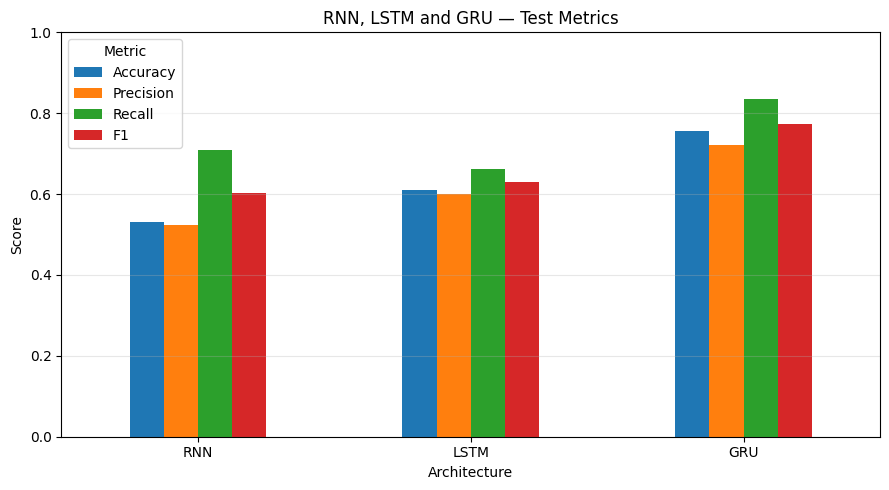

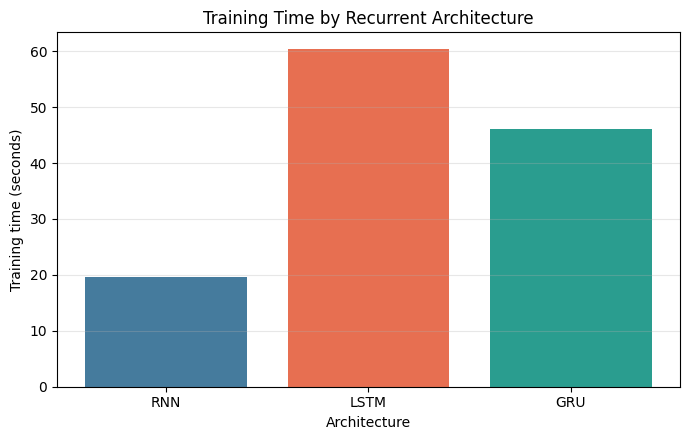

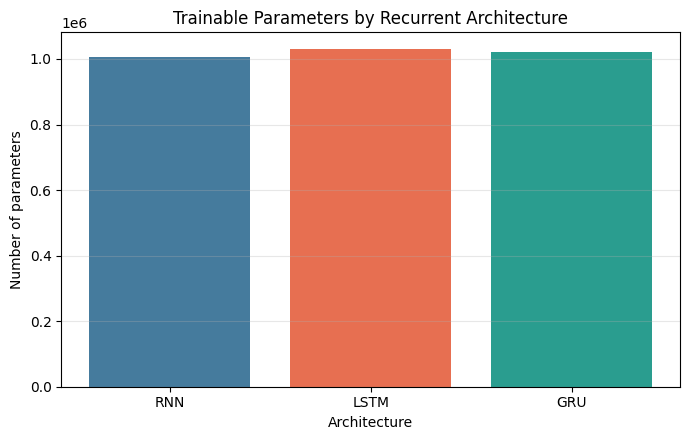

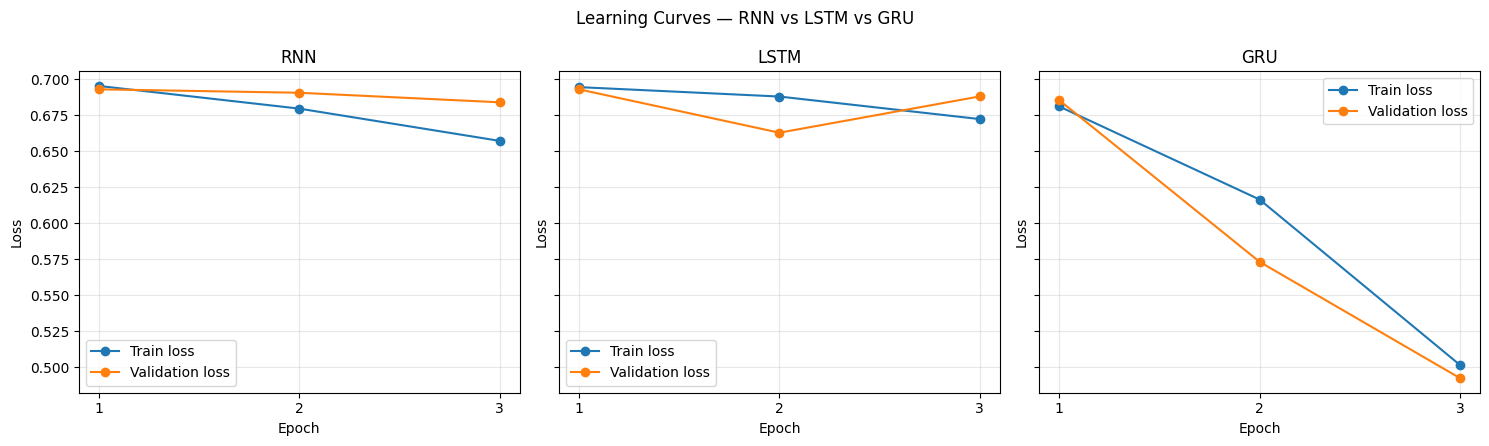

In [36]:
# So sánh bốn metrics trên test set
metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1']
fig, ax = plt.subplots(figsize=(9, 5))
exp4_results.set_index('Model')[metric_columns].plot(kind='bar', ax=ax)
ax.set(title='RNN, LSTM and GRU — Test Metrics', xlabel='Architecture', ylabel='Score', ylim=(0, 1))
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Metric')
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'rnn_lstm_gru_metrics.png', dpi=150)
plt.show()

# So sánh thời gian huấn luyện
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(exp4_results['Model'], exp4_results['Training time (s)'], color=['#457b9d', '#e76f51', '#2a9d8f'])
ax.set(title='Training Time by Recurrent Architecture', xlabel='Architecture', ylabel='Training time (seconds)')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'rnn_lstm_gru_training_time.png', dpi=150)
plt.show()

# So sánh số trainable parameters
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(exp4_results['Model'], exp4_results['Parameters'], color=['#457b9d', '#e76f51', '#2a9d8f'])
ax.set(title='Trainable Parameters by Recurrent Architecture', xlabel='Architecture', ylabel='Number of parameters')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'rnn_lstm_gru_parameters.png', dpi=150)
plt.show()

# Vẽ train/validation loss riêng cho mỗi kiến trúc
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, model_type in zip(axes, EXP4_MODEL_TYPES):
    history = exp4_histories[model_type]
    ax.plot(history['Epoch'], history['Train Loss'], marker='o', label='Train loss')
    ax.plot(history['Epoch'], history['Validation Loss'], marker='o', label='Validation loss')
    ax.set(title=model_type, xlabel='Epoch', ylabel='Loss', xticks=history['Epoch'])
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle('Learning Curves — RNN vs LSTM vs GRU')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'rnn_lstm_gru_learning_curves.png', dpi=150)
plt.show()

## 19.6 Comparison Analysis — phân tích tham khảo (AI hỗ trợ)

### Question
Kết quả thực nghiệm có phù hợp với prediction ban đầu không?

### Kết quả và câu trả lời dựa trên phép chạy
GRU đạt Accuracy và F1 cao nhất (0.7567 và 0.7743); RNN có hai giá trị thấp nhất (0.5311 và 0.6016). LSTM có 1,029,761 tham số (nhiều nhất), RNN có 1,007,489 (ít nhất) và cũng nhanh nhất trong ba recurrent model: 19.53 giây; GRU mất 46.16 giây, LSTM 60.35 giây. F1 và Accuracy cùng xếp GRU > LSTM > RNN. Ở lượt chạy này GRU/LSTM đều vượt RNN, nhưng chưa thể khái quát ngoài cấu hình và lượt chạy này. So với TF-IDF Logistic Regression (F1 0.8820, 2.20 giây), ba recurrent model không đạt F1 cao hơn; lưu ý cách đo thời gian baseline gồm fit TF-IDF.

Không thể trả lời phần ‘có phù hợp prediction ban đầu không’: notebook không có prediction trước experiment được lưu và không có dữ liệu Mục 10 ở đây. Không suy ngược prediction ban đầu từ kết quả đã xem. Long-range probe cũng chỉ gồm sáu câu và không cô lập hoàn hảo vị trí từ.

**Student verification:** tự đối chiếu prediction đã ghi trước experiment nếu có; xác nhận đánh đổi F1/thời gian theo mục tiêu, và không biến kết quả một seed/một lần chạy thành kết luận tổng quát.

# 20. Experiment 5 — Sequence Length

Dùng LSTM cố định và chỉ thay đổi max_length thành 50, 100 hoặc 200. Mỗi cấu hình khởi tạo model mới; split, vocabulary, tokenizer, optimizer, batch size, learning rate, epochs và tiêu chí chọn checkpoint được giữ nguyên như Experiment 4.

## 20.1 Thống kê token được giữ lại và chuẩn bị DataLoader

Độ dài gốc được tính bằng cùng hàm tokenize trên train. make_rnn_loader được tái sử dụng để mã hóa, truncation và padding; các review giữ nguyên split giữa mọi cấu hình.

In [37]:
MAX_LENGTH_VALUES = [50, 100, 200]
SEQUENCE_LENGTH_CONFIG = {
    'seed': 2026, 'embedding_dim': EXP4_CONFIG['embedding_dim'],
    'hidden_size': EXP4_CONFIG['hidden_size'], 'batch_size': EXP4_CONFIG['batch_size'],
    'learning_rate': EXP4_CONFIG['learning_rate'], 'epochs': EXP4_CONFIG['epochs'],
    'num_layers': EXP4_CONFIG['num_layers'], 'dropout': EXP4_CONFIG['dropout']
}

# Đếm token trước truncation bằng đúng tokenizer của các thí nghiệm trước
train_original_lengths = np.asarray(
    [len(tokenize(text)) for text in train_data['text'].astype(str)], dtype=np.int64
)
total_original_tokens = int(train_original_lengths.sum())
sequence_length_statistics = {}
sequence_length_stat_rows = []
for max_length in MAX_LENGTH_VALUES:
    retained_lengths = np.minimum(train_original_lengths, max_length)
    # Văn bản rỗng được mã hóa thành UNK để packed sequence có độ dài ít nhất là một
    encoded_lengths = np.minimum(np.maximum(train_original_lengths, 1), max_length)
    retained_tokens = int(retained_lengths.sum())
    stats = {
        'Max length': max_length,
        '% tokens retained': retained_tokens / total_original_tokens * 100 if total_original_tokens else 0.0,
        'Reviews truncated': int(np.sum(train_original_lengths > max_length)),
        '% reviews truncated': float(np.mean(train_original_lengths > max_length) * 100) if len(train_original_lengths) else 0.0,
        'Mean retained sequence length': float(retained_lengths.mean()) if len(retained_lengths) else 0.0,
        'Mean padding tokens': float((max_length - encoded_lengths).mean()) if len(encoded_lengths) else 0.0
    }
    sequence_length_statistics[max_length] = stats
    sequence_length_stat_rows.append(stats)
display(pd.DataFrame(sequence_length_stat_rows).style.format({
    '% tokens retained': '{:.2f}%', '% reviews truncated': '{:.2f}%',
    'Mean retained sequence length': '{:.2f}', 'Mean padding tokens': '{:.2f}'
}))

EXP5_RESULTS_DIR = LAB_DIR / 'results'
EXP5_CHECKPOINT_DIR = LAB_DIR / 'models' / 'sequence_length'
EXP5_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EXP5_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print('Cấu hình LSTM cố định:', SEQUENCE_LENGTH_CONFIG)
print('Device:', DEVICE)

,Max length,% tokens retained,Reviews truncated,% reviews truncated,Mean retained sequence length,Mean padding tokens
0,50,21.21%,19537,97.69%,49.80,0.20
1,100,41.03%,17606,88.03%,96.32,3.68
2,200,68.02%,8356,41.78%,159.69,40.31


Cấu hình LSTM cố định: {'seed': 2026, 'embedding_dim': 50, 'hidden_size': 64, 'batch_size': 64, 'learning_rate': 0.001, 'epochs': 3, 'num_layers': 1, 'dropout': 0.0}
Device: cpu


### Đo memory usage nếu khả thi

CUDA được đo bằng peak allocated memory tăng thêm so với mức trước lượt chạy. CPU dùng peak RSS của process nếu có psutil. CPU RSS và GPU allocated memory là các đại lượng khác nhau, không so sánh trực tiếp; nếu không đo được sẽ ghi Not measured.

In [38]:
import threading
try:
    import psutil
except ImportError:
    psutil = None

class PeakRSSSampler:
    def __init__(self, interval=0.05):
        self.interval = interval
        self.process = psutil.Process()
        self.baseline = self.process.memory_info().rss
        self.peak = self.baseline
        self.stop_event = threading.Event()
        self.thread = threading.Thread(target=self._sample, daemon=True)

    def _sample(self):
        while not self.stop_event.is_set():
            self.peak = max(self.peak, self.process.memory_info().rss)
            self.stop_event.wait(self.interval)

    def start(self):
        self.thread.start()

    def stop(self):
        self.stop_event.set()
        self.thread.join()
        self.peak = max(self.peak, self.process.memory_info().rss)
        return max(0, self.peak - self.baseline) / (1024 ** 2)

def synchronize_cuda():
    # Đồng bộ GPU trước khi chụp thời gian hoặc peak memory
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(DEVICE)

## 20.2 Huấn luyện LSTM cho từng max_length

Hàm train_model của Experiment 4 được tái sử dụng; đồng hồ bên ngoài bao trọn training/validation loop nhưng không tính chuẩn bị DataLoader. Khi dùng CUDA, thiết bị được đồng bộ trước và sau khoảng đo.

In [39]:
sequence_length_rows = []
sequence_length_histories = {}

for max_length in MAX_LENGTH_VALUES:
    # Tạo lại model với cùng seed, không tiếp tục model của độ dài trước
    random.seed(SEQUENCE_LENGTH_CONFIG['seed'])
    np.random.seed(SEQUENCE_LENGTH_CONFIG['seed'])
    torch.manual_seed(SEQUENCE_LENGTH_CONFIG['seed'])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEQUENCE_LENGTH_CONFIG['seed'])

    # Các review và vocabulary giữ nguyên; chỉ max_length thay đổi
    train_loader_length = make_rnn_loader(train_data, vocab, max_length, SEQUENCE_LENGTH_CONFIG['batch_size'], shuffle=True)
    val_loader_length = make_rnn_loader(val_data, vocab, max_length, SEQUENCE_LENGTH_CONFIG['batch_size'])
    test_loader_length = make_rnn_loader(test_data, vocab, max_length, SEQUENCE_LENGTH_CONFIG['batch_size'])

    cpu_sampler = None
    gpu_baseline_bytes = None
    if DEVICE.type == 'cuda':
        synchronize_cuda()
        gpu_baseline_bytes = torch.cuda.memory_allocated(DEVICE)
        torch.cuda.reset_peak_memory_stats(DEVICE)
    elif psutil is not None:
        cpu_sampler = PeakRSSSampler()
        cpu_sampler.start()

    model = RecurrentSentimentClassifier(
        vocab_size=len(vocab), embedding_dim=SEQUENCE_LENGTH_CONFIG['embedding_dim'],
        hidden_size=SEQUENCE_LENGTH_CONFIG['hidden_size'], model_type='LSTM',
        num_layers=SEQUENCE_LENGTH_CONFIG['num_layers'],
        dropout=SEQUENCE_LENGTH_CONFIG['dropout']
    ).to(DEVICE)

    synchronize_cuda()
    training_start = time.perf_counter()
    model, history, _, best_epoch, epochs_trained = train_model(
        model, train_loader_length, val_loader_length,
        {**SEQUENCE_LENGTH_CONFIG, 'max_length': max_length}
    )
    synchronize_cuda()
    training_time = time.perf_counter() - training_start

    if DEVICE.type == 'cuda':
        peak_bytes = torch.cuda.max_memory_allocated(DEVICE)
        memory_mb = max(0, peak_bytes - gpu_baseline_bytes) / (1024 ** 2)
        memory_method = 'Incremental CUDA peak allocated memory (MB)'
    elif cpu_sampler is not None:
        memory_mb = cpu_sampler.stop()
        memory_method = 'Incremental peak process RSS (MB)'
    else:
        memory_mb = 'Not measured'
        memory_method = 'Not measured (psutil unavailable on CPU)'

    # Báo validation loss tại checkpoint F1 tốt nhất và loss thấp nhất toàn quá trình
    selected_row = history.loc[history['Epoch'] == best_epoch].iloc[0]
    best_validation_loss = float(history['Validation Loss'].min())
    selected_validation_loss = float(selected_row['Validation Loss'])

    # Chỉ đánh giá test sau khi checkpoint đã chọn xong bằng validation
    test_metrics = evaluate_model(model, test_loader_length)
    stats = sequence_length_statistics[max_length]
    sequence_length_rows.append({
        **stats, 'Training time (s)': training_time,
        'Validation loss': selected_validation_loss,
        'Best validation loss': best_validation_loss,
        'Test F1': test_metrics['F1'], 'Test Accuracy': test_metrics['Accuracy'],
        'Test Precision': test_metrics['Precision'], 'Test Recall': test_metrics['Recall'],
        'Best checkpoint epoch': best_epoch, 'Epochs trained': epochs_trained,
        'Memory (MB)': memory_mb, 'Memory method': memory_method, 'Device': str(DEVICE)
    })
    sequence_length_histories[max_length] = history
    history.to_csv(EXP5_RESULTS_DIR / f'sequence_length_{max_length}_history.csv', index=False)
    torch.save({
        'model_type': 'LSTM', 'max_length': max_length,
        'state_dict': model.state_dict(), 'config': SEQUENCE_LENGTH_CONFIG,
        'vocab_size': len(vocab)
    }, EXP5_CHECKPOINT_DIR / f'lstm_max_length_{max_length}_best.pt')

    # Giải phóng model trước cấu hình tiếp theo để hạn chế bộ nhớ tích lũy
    model.to('cpu')
    del model, train_loader_length, val_loader_length, test_loader_length
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

sequence_length_results = pd.DataFrame(sequence_length_rows)
main_columns = ['Max length', '% tokens retained', 'Training time (s)',
                'Validation loss', 'Test F1', 'Memory (MB)']
display(sequence_length_results[main_columns].style.format({
    '% tokens retained': '{:.2f}%', 'Training time (s)': '{:.2f}',
    'Validation loss': '{:.4f}', 'Test F1': '{:.4f}'
}))
sequence_length_csv = EXP5_RESULTS_DIR / 'sequence_length_comparison.csv'
sequence_length_results.to_csv(sequence_length_csv, index=False)
print('Đã lưu kết quả:', sequence_length_csv)

LSTM | epoch 1/3 | train_loss=0.6816 | val_loss=0.6547 | val_f1=0.6587


LSTM | epoch 2/3 | train_loss=0.5986 | val_loss=0.5717 | val_f1=0.6960


LSTM | epoch 3/3 | train_loss=0.5051 | val_loss=0.5250 | val_f1=0.7298


LSTM | epoch 1/3 | train_loss=0.6944 | val_loss=0.6928 | val_f1=0.6027


LSTM | epoch 2/3 | train_loss=0.6878 | val_loss=0.6627 | val_f1=0.6370


...

LSTM | epoch 1/3 | train_loss=0.6760 | val_loss=0.6865 | val_f1=0.4613


LSTM | epoch 2/3 | train_loss=0.6515 | val_loss=0.6343 | val_f1=0.6313


LSTM | epoch 3/3 | train_loss=0.5662 | val_loss=0.5403 | val_f1=0.7718


,Max length,% tokens retained,Training time (s),Validation loss,Test F1,Memory (MB)
0,50,21.21%,22.45,0.5250,0.7118,34.062500
1,100,41.03%,58.49,0.6627,0.6303,23.437500
2,200,68.02%,187.68,0.5403,0.7691,52.812500


Đã lưu kết quả: /home/nguyenducthang/NLP/Lab5/results/sequence_length_comparison.csv


## 20.3 Biểu đồ và learning curves

Hai biểu đồ chính biểu diễn Test F1 và training time theo max_length. Learning curves được lưu riêng cho Experiment 5.

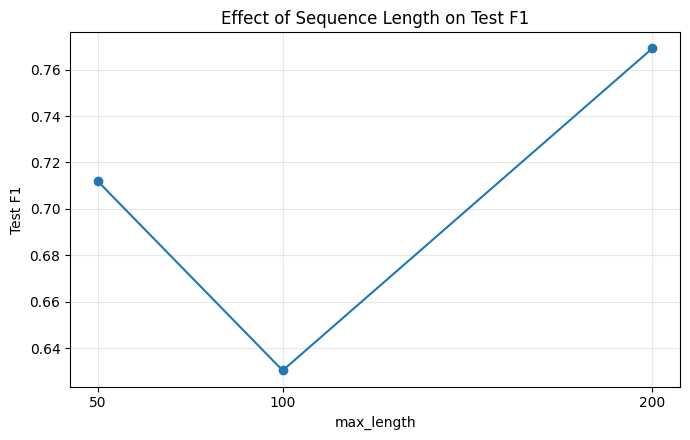

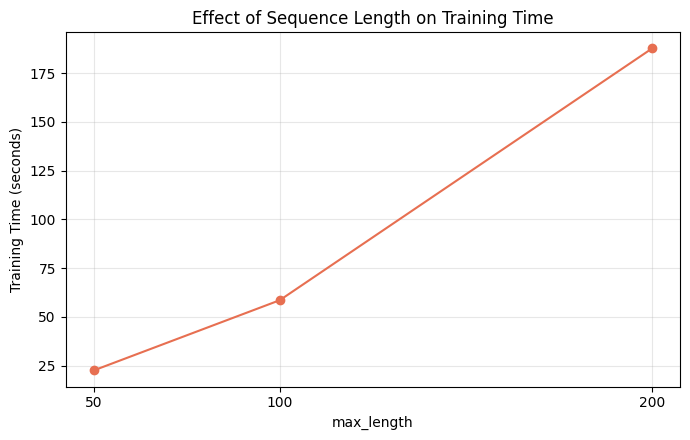

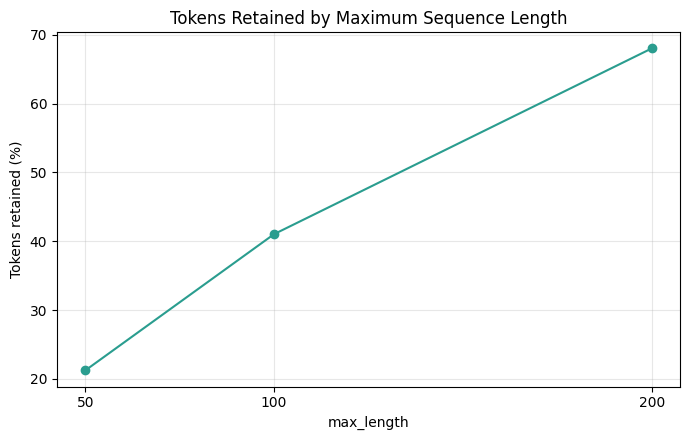

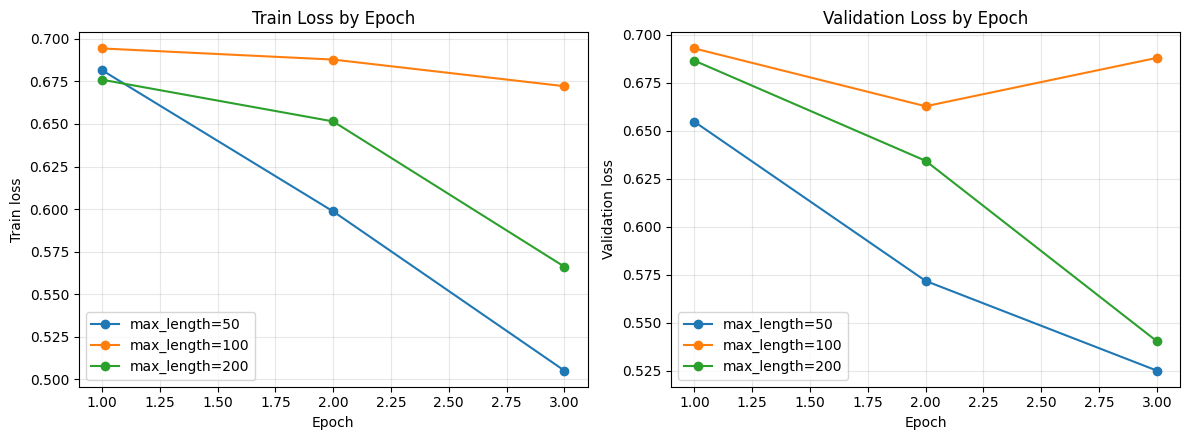

Đã lưu hình Experiment 5 trong: /home/nguyenducthang/NLP/Lab5/figures


In [40]:
# max_length so với Test F1
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sequence_length_results['Max length'], sequence_length_results['Test F1'], marker='o')
ax.set(title='Effect of Sequence Length on Test F1', xlabel='max_length', ylabel='Test F1')
ax.set_xticks(MAX_LENGTH_VALUES)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_test_f1.png', dpi=150)
plt.show()

# max_length so với training time
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sequence_length_results['Max length'], sequence_length_results['Training time (s)'], marker='o', color='#e76f51')
ax.set(title='Effect of Sequence Length on Training Time', xlabel='max_length', ylabel='Training Time (seconds)')
ax.set_xticks(MAX_LENGTH_VALUES)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_training_time.png', dpi=150)
plt.show()

# Tỷ lệ token được giữ lại
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sequence_length_results['Max length'], sequence_length_results['% tokens retained'], marker='o', color='#2a9d8f')
ax.set(title='Tokens Retained by Maximum Sequence Length', xlabel='max_length', ylabel='Tokens retained (%)')
ax.set_xticks(MAX_LENGTH_VALUES)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_tokens_retained.png', dpi=150)
plt.show()

# Learning curves train loss và validation loss cho ba cấu hình
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for max_length in MAX_LENGTH_VALUES:
    history = sequence_length_histories[max_length]
    axes[0].plot(history['Epoch'], history['Train Loss'], marker='o', label=f'max_length={max_length}')
    axes[1].plot(history['Epoch'], history['Validation Loss'], marker='o', label=f'max_length={max_length}')
axes[0].set(title='Train Loss by Epoch', xlabel='Epoch', ylabel='Train loss')
axes[1].set(title='Validation Loss by Epoch', xlabel='Epoch', ylabel='Validation loss')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sequence_length_learning_curves.png', dpi=150)
plt.show()
print('Đã lưu hình Experiment 5 trong:', FIGURES_DIR)

## 20.4 Analysis Question — phân tích tham khảo (AI hỗ trợ)

### Question
Có tồn tại trade-off giữa context và computational cost không?

### Experimental Evidence
Dùng bảng kết quả thực tế để đối chiếu token retention, training time, validation loss tại checkpoint chọn theo Validation F1, Test F1 và memory usage nếu đo được.

### Answer dựa trên phép chạy
Có trade-off quan sát được. Từ max_length 50 lên 100 rồi 200, tỷ lệ token giữ lại tăng 21.21% → 41.03% → 68.02%, trong khi thời gian tăng 22.45 → 58.49 → 187.68 giây. Test F1 là 0.7118 → 0.6303 → 0.7691 nên không tăng đơn điệu; 100 giữ thêm token so với 50 nhưng F1 thấp hơn 0.0815. Từ 50 đến 200, F1 tăng 0.0573 nhưng tốn thêm 165.23 giây. CPU RSS đo được lần lượt 34.06, 23.44, 52.81 MB; đây là incremental process RSS, phụ thuộc runtime và không tăng đơn điệu, không nên diễn giải như bộ nhớ model chính xác.

**Kết luận tham khảo:** trong cấu hình/lần chạy này 200 cho F1 cao nhất nhưng đắt thời gian nhất; chưa có cơ sở khẳng định lựa chọn tối ưu phổ quát.

**Student verification:** cân nhắc ngân sách thời gian và ứng dụng; kiểm tra validation loss và việc chọn checkpoint theo Validation F1 trước khi tự chốt cấu hình.

# 21. Experiment 6 — Long-range Dependency

Thí nghiệm quan sát xem dự đoán thay đổi thế nào khi keyword sentiment xuất hiện ở đầu, giữa hoặc cuối câu. Đây là quan sát đầu ra; vài câu kiểm thử không chứng minh vanishing gradient.

## 21.1 Các câu kiểm thử

Tạo sáu câu: hai keyword (excellent/terrible) ở ba vị trí. Các câu dùng bối cảnh gần giống nhau nhưng không hoàn toàn cùng token/ cấu trúc; vì vậy cần ghi nhận đây là giới hạn của thiết kế kiểm soát. Token index và relative position sẽ được tính bằng tokenizer thực tế.

In [41]:
LONG_RANGE_CASES = [
    {
        'Sentence ID': 'excellent_beginning', 'Keyword': 'excellent',
        'Expected Sentiment': 'Positive', 'Position': 'beginning',
        'Text': 'Excellent is my impression after watching this movie and considering its story, characters, acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions.'
    },
    {
        'Sentence ID': 'excellent_middle', 'Keyword': 'excellent',
        'Expected Sentiment': 'Positive', 'Position': 'middle',
        'Text': 'I watched this movie at home and considered its story, characters, excellent acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions.'
    },
    {
        'Sentence ID': 'excellent_end', 'Keyword': 'excellent',
        'Expected Sentiment': 'Positive', 'Position': 'end',
        'Text': 'I watched this movie at home and considered its story, characters, acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions; overall, I would call it excellent.'
    },
    {
        'Sentence ID': 'terrible_beginning', 'Keyword': 'terrible',
        'Expected Sentiment': 'Negative', 'Position': 'beginning',
        'Text': 'Terrible is my impression after watching this movie and considering its story, characters, acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions.'
    },
    {
        'Sentence ID': 'terrible_middle', 'Keyword': 'terrible',
        'Expected Sentiment': 'Negative', 'Position': 'middle',
        'Text': 'I watched this movie at home and considered its story, characters, terrible acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions.'
    },
    {
        'Sentence ID': 'terrible_end', 'Keyword': 'terrible',
        'Expected Sentiment': 'Negative', 'Position': 'end',
        'Text': 'I watched this movie at home and considered its story, characters, acting, camera work, dialogue, setting, soundtrack, pacing, costumes, and scene transitions; overall, I would call it terrible.'
    }
]
print('Số câu kiểm thử:', len(LONG_RANGE_CASES))
display(pd.DataFrame(LONG_RANGE_CASES)[['Sentence ID', 'Keyword', 'Expected Sentiment', 'Position', 'Text']])

Số câu kiểm thử: 6


,Sentence ID,Keyword,Expected Sentiment,Position,Text
0,excellent_beginning,excellent,Positive,beginning,Excellent is my impression after watching this...
1,excellent_middle,excellent,Positive,middle,I watched this movie at home and considered it...
2,excellent_end,excellent,Positive,end,I watched this movie at home and considered it...
3,terrible_beginning,terrible,Negative,beginning,Terrible is my impression after watching this ...
4,terrible_middle,terrible,Negative,middle,I watched this movie at home and considered it...
5,terrible_end,terrible,Negative,end,I watched this movie at home and considered it...


## 21.2 Tái sử dụng model đã huấn luyện

Ưu tiên các model đang có trong exp4_models. Nếu notebook được mở lại, thử tải checkpoint Experiment 4 tương thích. Không khởi tạo model để train và không gọi training function.

In [42]:
long_range_models = {}
long_range_checkpoint_dir = globals().get(
    'EXP4_CHECKPOINT_DIR', LAB_DIR / 'models' / 'rnn_lstm_gru'
)

for model_type in ['RNN', 'LSTM', 'GRU']:
    # Dùng model đã train trong phiên notebook nếu có
    trained_models = globals().get('exp4_models', {})
    if model_type in trained_models:
        model = trained_models[model_type].to(DEVICE)
        model.eval()
        config = globals().get('EXP4_CONFIG', {})
        long_range_models[model_type] = {
            'model': model, 'max_length': int(config.get('max_length', MAX_LENGTH))
        }
        print(f'{model_type}: dùng model đã train trong Experiment 4')
        continue

    checkpoint_path = long_range_checkpoint_dir / f'{model_type.lower()}_best.pt'
    if not checkpoint_path.is_file():
        print(f'{model_type}: không có checkpoint tại {checkpoint_path}')
        continue

    try:
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
        checkpoint_config = checkpoint.get('config', {})
        if checkpoint.get('vocab_size') != len(vocab):
            print(f'{model_type}: bỏ qua checkpoint vì vocabulary size không khớp')
            continue
        model = RecurrentSentimentClassifier(
            vocab_size=len(vocab),
            embedding_dim=checkpoint_config.get('embedding_dim', EXP4_CONFIG['embedding_dim']),
            hidden_size=checkpoint_config.get('hidden_size', EXP4_CONFIG['hidden_size']),
            model_type=model_type,
            num_layers=checkpoint_config.get('num_layers', EXP4_CONFIG['num_layers']),
            dropout=checkpoint_config.get('dropout', EXP4_CONFIG['dropout'])
        ).to(DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()
        long_range_models[model_type] = {
            'model': model,
            'max_length': int(checkpoint_config.get('max_length', MAX_LENGTH))
        }
        print(f'{model_type}: đã tải checkpoint Experiment 4')
    except (KeyError, RuntimeError, OSError) as error:
        print(f'{model_type}: checkpoint không tương thích hoặc không đọc được: {error}')

if not long_range_models:
    print('Chưa có model/checkpoint phù hợp. Hãy chạy Experiment 4 trước; Experiment 6 không huấn luyện lại model.')
else:
    print('Models dùng được:', list(long_range_models))

RNN: dùng model đã train trong Experiment 4
LSTM: dùng model đã train trong Experiment 4
GRU: dùng model đã train trong Experiment 4
Models dùng được: ['RNN', 'LSTM', 'GRU']


## 21.3 Dự đoán và xác định vị trí keyword

Inference dùng tokenizer, vocabulary, padding/truncation và max_length gắn với model. Truncated cho biết keyword có bị cắt khỏi chuỗi đầu vào hay không; sequence_truncated báo chuỗi có bị cắt bất kỳ token nào hay không.

In [43]:
def predict_sentiment(model, text, vocab, max_length):
    # Dùng đúng tokenizer và vocabulary đã có từ các experiment trước
    tokens = tokenize(text)
    token_ids = [vocab.get(token, UNK_ID) for token in tokens]
    sequence_truncated = len(token_ids) > max_length
    model_ids = token_ids[:max_length]
    if not model_ids:
        model_ids = [UNK_ID]  # Sequence rỗng cần một UNK để pack được
    actual_length = len(model_ids)
    padded_ids = model_ids + [PAD_ID] * (max_length - actual_length)
    input_tensor = torch.tensor([padded_ids], dtype=torch.long, device=DEVICE)
    length_tensor = torch.tensor([actual_length], dtype=torch.long, device=DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor, length_tensor)
        positive_probability = torch.sigmoid(logits).item()
    predicted_label = 'Positive' if positive_probability >= 0.5 else 'Negative'
    return {
        'tokens': tokens, 'positive_probability': positive_probability,
        'predicted_label': predicted_label, 'sequence_truncated': sequence_truncated,
        'actual_length': actual_length
    }

long_range_rows = []
if long_range_models:
    for model_name, model_info in long_range_models.items():
        model = model_info['model']
        max_length = model_info['max_length']
        for case in LONG_RANGE_CASES:
            prediction = predict_sentiment(model, case['Text'], vocab, max_length)
            tokens = prediction['tokens']
            keyword_positions = [index for index, token in enumerate(tokens) if token == case['Keyword']]
            keyword_index = keyword_positions[0] if keyword_positions else None
            keyword_truncated = keyword_index is not None and keyword_index >= max_length
            # Nếu keyword vắng khỏi tokens thì không thể gán cho model một điểm số vị trí
            if keyword_index is None:
                keyword_truncated = case['Keyword'] in tokenize(case['Text'])
            expected = case['Expected Sentiment']
            long_range_rows.append({
                'Model': model_name, 'Sentence ID': case['Sentence ID'],
                'Keyword': case['Keyword'], 'Expected': expected,
                'Position': case['Position'], 'Token index': keyword_index,
                'Relative position': (keyword_index / len(tokens)) if keyword_index is not None and tokens else np.nan,
                'Total sequence length': len(tokens), 'Model max_length': max_length,
                'Predicted': prediction['predicted_label'],
                'P(positive)': prediction['positive_probability'],
                'Correct': prediction['predicted_label'] == expected,
                'Sequence truncated': prediction['sequence_truncated'],
                'Truncated': bool(keyword_truncated)
            })

long_range_results = pd.DataFrame(long_range_rows)
if not long_range_results.empty:
    display(long_range_results.style.format({
        'Relative position': '{:.3f}', 'P(positive)': '{:.4f}'
    }))
    long_range_results_path = LAB_DIR / 'results' / 'long_range_dependency_results.csv'
    long_range_results_path.parent.mkdir(parents=True, exist_ok=True)
    long_range_results.to_csv(long_range_results_path, index=False)
    print('Đã lưu kết quả:', long_range_results_path)
else:
    print('Không có prediction để lưu vì chưa có checkpoint tương thích.')

,Model,Sentence ID,Keyword,Expected,Position,Token index,Relative position,Total sequence length,Model max_length,Predicted,P(positive),Correct,Sequence truncated,Truncated
0,RNN,excellent_beginning,excellent,Positive,beginning,0,0.000,24,100,Positive,0.6017,True,False,False
1,RNN,excellent_middle,excellent,Positive,middle,11,0.478,23,100,Positive,0.6036,True,False,False
2,RNN,excellent_end,excellent,Positive,end,27,0.964,28,100,Positive,0.5263,True,False,False
3,RNN,terrible_beginning,terrible,Negative,beginning,0,0.000,24,100,Positive,0.6016,False,False,False
4,RNN,terrible_middle,terrible,Negative,middle,11,0.478,23,100,Positive,0.6011,False,False,False
5,RNN,terrible_end,terrible,Negative,end,27,0.964,28,100,Positive,0.5160,False,False,False
6,LSTM,excellent_beginning,excellent,Positive,beginning,0,0.000,24,100,Positive,0.6813,True,False,False
7,LSTM,excellent_middle,excellent,Positive,middle,11,0.478,23,100,Positive,0.6936,True,False,False
8,LSTM,excellent_end,excellent,Positive,end,27,0.964,28,100,Positive,0.6934,True,False,False
9,LSTM,terrible_beginning,terrible,Negative,beginning,0,0.000,24,100,Positive,0.6430,False,False,False


Đã lưu kết quả: /home/nguyenducthang/NLP/Lab5/results/long_range_dependency_results.csv


## 21.4 So sánh theo vị trí keyword

Bảng tổng hợp hiển thị trung bình xác suất và độ chính xác theo model/keyword/position. Delta end − beginning chỉ là chênh lệch xác suất dự đoán; không phải phép đo trực tiếp của vanishing gradient.

In [44]:
if not long_range_results.empty:
    position_order = ['beginning', 'middle', 'end']
    position_summary = (
        long_range_results.groupby(['Model', 'Keyword', 'Position'], as_index=False)
        .agg(**{
            'P(positive)': ('P(positive)', 'mean'),
            'Correct rate': ('Correct', 'mean'),
            'Predicted labels': ('Predicted', lambda values: ', '.join(values))
        })
    )
    position_summary['Position'] = pd.Categorical(
        position_summary['Position'], categories=position_order, ordered=True
    )
    position_summary = position_summary.sort_values(['Model', 'Keyword', 'Position'])
    display(position_summary.style.format({
        'P(positive)': '{:.4f}', 'Correct rate': '{:.3f}'
    }))

    probability_pivot = position_summary.pivot(
        index=['Model', 'Keyword'], columns='Position', values='P(positive)'
    )
    if {'beginning', 'end'}.issubset(probability_pivot.columns):
        probability_pivot['Delta end - beginning'] = probability_pivot['end'] - probability_pivot['beginning']
    display(probability_pivot)
    position_summary.to_csv(LAB_DIR / 'results' / 'long_range_dependency_position_summary.csv')
else:
    position_summary = pd.DataFrame()
    probability_pivot = pd.DataFrame()
    print('Bỏ qua tổng hợp vì chưa có kết quả dự đoán.')

,Model,Keyword,Position,P(positive),Correct rate,Predicted labels
0,GRU,excellent,beginning,0.7760,1.000,Positive
2,GRU,excellent,middle,0.8128,1.000,Positive
1,GRU,excellent,end,0.8289,1.000,Positive
3,GRU,terrible,beginning,0.4414,1.000,Negative
5,GRU,terrible,middle,0.6285,0.000,Positive
4,GRU,terrible,end,0.5421,0.000,Positive
6,LSTM,excellent,beginning,0.6813,1.000,Positive
8,LSTM,excellent,middle,0.6936,1.000,Positive
7,LSTM,excellent,end,0.6934,1.000,Positive
9,LSTM,terrible,beginning,0.6430,0.000,Positive


Position         beginning    middle       end  Delta end - beginning
Model Keyword                                                        
GRU   excellent   0.775951  0.812802  0.828914               0.052964
      terrible    0.441411  0.628538  0.542091               0.100679
LSTM  excellent   0.681271  0.693608  0.693424               0.012153
      terrible    0.643041  0.673467  0.666192               0.023150
RNN   excellent   0.601706  0.603570  0.526309              -0.075396
      terrible    0.601580  0.601084  0.516022              -0.085558

## 21.5 Visualization

Mỗi model và keyword có đường riêng để không gộp xác suất của sentiment khác nhau.

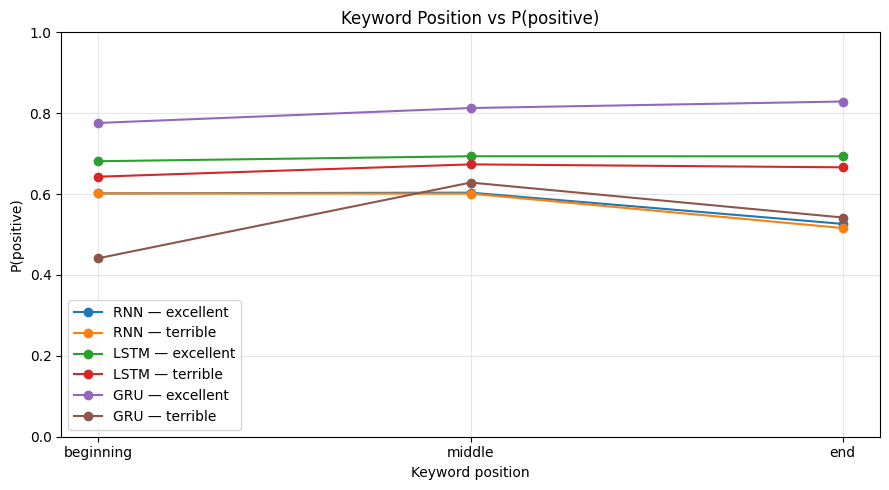

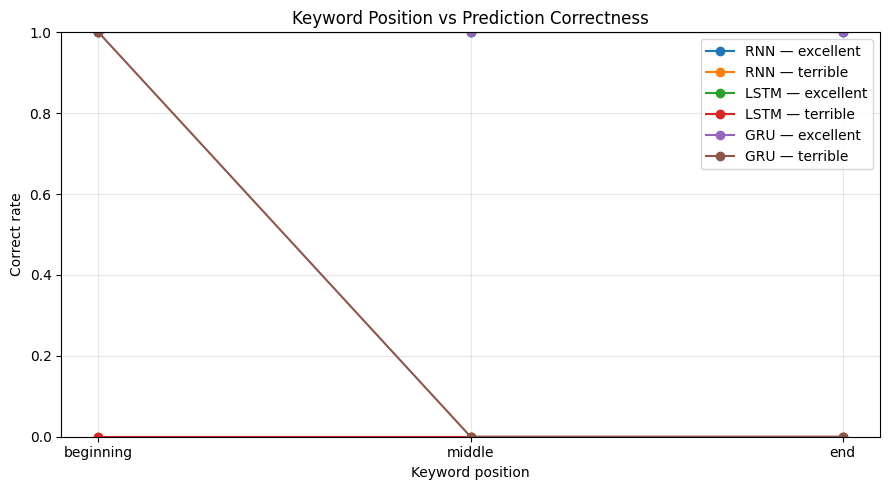

In [45]:
if not long_range_results.empty:
    plot_positions = ['beginning', 'middle', 'end']

    # Xác suất Positive theo vị trí, tách đường theo model và keyword
    fig, ax = plt.subplots(figsize=(9, 5))
    for model_name in long_range_results['Model'].unique():
        for keyword in ['excellent', 'terrible']:
            selected = position_summary[
                (position_summary['Model'] == model_name) &
                (position_summary['Keyword'] == keyword)
            ].sort_values('Position')
            if not selected.empty:
                ax.plot(selected['Position'].astype(str), selected['P(positive)'],
                        marker='o', label=f'{model_name} — {keyword}')
    ax.set(title='Keyword Position vs P(positive)', xlabel='Keyword position', ylabel='P(positive)')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(LAB_DIR / 'figures' / 'long_range_dependency_probability.png', dpi=150)
    plt.show()

    # Tỷ lệ prediction đúng theo vị trí, cũng tách riêng keyword/model
    fig, ax = plt.subplots(figsize=(9, 5))
    for model_name in long_range_results['Model'].unique():
        for keyword in ['excellent', 'terrible']:
            selected = position_summary[
                (position_summary['Model'] == model_name) &
                (position_summary['Keyword'] == keyword)
            ].sort_values('Position')
            if not selected.empty:
                ax.plot(selected['Position'].astype(str), selected['Correct rate'],
                        marker='o', label=f'{model_name} — {keyword}')
    ax.set(title='Keyword Position vs Prediction Correctness', xlabel='Keyword position', ylabel='Correct rate')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(LAB_DIR / 'figures' / 'long_range_dependency_correctness.png', dpi=150)
    plt.show()
else:
    print('Không tạo biểu đồ vì chưa có kết quả dự đoán.')

## 21.6 Empirical Observation — phân tích tham khảo (AI hỗ trợ)

**Observed Results:** Tất cả câu có `excellent` được cả ba model dự đoán Positive ở đầu/giữa/cuối; P(positive) của GRU lần lượt 0.7760/0.8128/0.8289, LSTM 0.6813/0.6936/0.6934, RNN 0.6017/0.6036/0.5263. Với `terrible`, chỉ GRU ở vị trí đầu dự đoán đúng Negative (P+=0.4414); GRU dự đoán Positive khi từ nằm giữa/cuối (0.6285/0.5421), LSTM và RNN đều dự đoán Positive ở cả ba vị trí. Không câu nào bị truncation. Câu thử tương tự nhưng không được khống chế hoàn toàn giống nhau, vì vậy vị trí từ không phải biến duy nhất chắc chắn thay đổi.

**Theoretical explanation (khả năng, không phải kết luận thực nghiệm):** trạng thái recurrent được cập nhật qua từng timestep; tín hiệu từ đầu chuỗi phải truyền qua nhiều bước để tác động lên biểu diễn cuối. LSTM/GRU có cổng điều tiết luồng trạng thái, nhưng kết quả sáu câu này không đo gradient và không chứng minh vanishing gradient, cũng không chứng minh cổng là nguyên nhân của chênh lệch. Cần bộ câu được kiểm soát chặt hơn, nhiều mẫu và thí nghiệm trực tiếp trên gradient/hidden states để kiểm tra cơ chế.

**Student verification:** tự quyết định cách diễn giải dựa trên evidence; không gán nguyên nhân nhân quả cho kiến trúc chỉ từ các prediction này.

# 22. Evaluation

Đánh giá Logistic Regression và ba recurrent models trên cùng IMDb test split. Các checkpoint RNN/LSTM/GRU được chọn bằng Validation F1; Test chỉ dùng cho đánh giá cuối.

## 22.1 Metrics và confusion matrix

**Phân tích kết quả thực tế (AI hỗ trợ):** Trên test gồm 25,000 review, Logistic Regression có Accuracy/Precision/Recall/F1 = 0.8817/0.8797/0.8843/0.8820; RNN = 0.5311/0.5230/0.7082/0.6016; LSTM = 0.6112/0.6007/0.6630/0.6303; GRU = 0.7567/0.7221/0.8346/0.7743. Confusion counts (TN, FP, FN, TP): LR (10988,1512,1446,11054), RNN (4426,8074,3648,8852), LSTM (6992,5508,4213,8287), GRU (8485,4015,2067,10433). Test có 12,500 mẫu mỗi lớp. Trong các model này LR có ít lỗi nhất (2,958), RNN nhiều nhất (11,722); lỗi FP nhiều hơn FN ở cả bốn model. Các số này mô tả lỗi đếm được, không giải thích nguyên nhân ngôn ngữ.

**Student verification:** kiểm tra hàng/column confusion matrix theo đúng thứ tự label [0,1]. Precision phản ánh FP trong dự đoán Positive; Recall Positive phản ánh FN. Không suy ra nguyên nhân chỉ từ confusion matrix.

,Model,Parameters,Training time (s),Epochs,Sequence length,Vocabulary size,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Logistic Regression,10001,2.20,N/A,N/A,10000,0.8817,0.8797,0.8843,0.8820,10988,1512,1446,11054
1,RNN,1007489,19.53,3,100,20000,0.5311,0.5230,0.7082,0.6016,4426,8074,3648,8852
2,LSTM,1029761,60.35,3,100,20000,0.6112,0.6007,0.6630,0.6303,6992,5508,4213,8287
3,GRU,1022337,46.16,3,100,20000,0.7567,0.7221,0.8346,0.7743,8485,4015,2067,10433


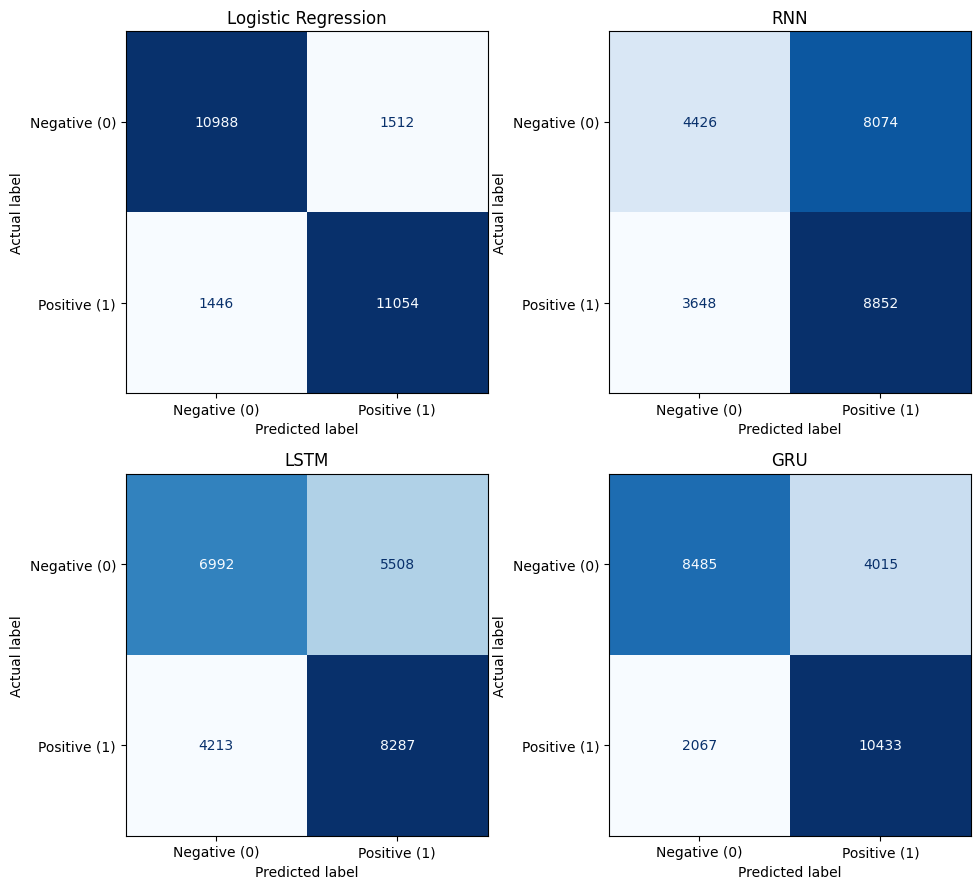

Saved: /home/nguyenducthang/NLP/Lab5/results/evaluation_summary.csv /home/nguyenducthang/NLP/Lab5/figures/confusion_matrix.png


In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Lấy dự đoán từ các model đã huấn luyện, không fit hoặc train lại
EVALUATION_RESULTS_DIR = LAB_DIR / 'results'
EVALUATION_FIGURES_DIR = LAB_DIR / 'figures'
EVALUATION_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

evaluation_predictions = {
    'Logistic Regression': np.asarray(tfidf_test_pred, dtype=np.int64)
}
evaluation_models = {'Logistic Regression': tfidf_lr_model}
for model_type in ['RNN', 'LSTM', 'GRU']:
    details, labels_from_model, predictions, probabilities, logits = evaluate_rnn(
        exp4_models[model_type], test_loader, DEVICE
    )
    if not np.array_equal(labels_from_model, y_test):
        raise ValueError(f'Test labels/order không khớp với y_test cho {model_type}')
    evaluation_predictions[model_type] = predictions
    evaluation_models[model_type] = exp4_models[model_type]

evaluation_rows = []
for model_name, predictions in evaluation_predictions.items():
    truth = y_test
    metrics = classification_metrics(truth, predictions)
    matrix = confusion_matrix(truth, predictions, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    # Xác minh metric tính từ confusion matrix khớp với sklearn
    total = tn + fp + fn + tp
    calculated = {
        'Accuracy': (tp + tn) / total if total else np.nan,
        'Precision': tp / (tp + fp) if (tp + fp) else 0.0,
        'Recall': tp / (tp + fn) if (tp + fn) else 0.0,
    }
    calculated['F1'] = (
        2 * calculated['Precision'] * calculated['Recall'] /
        (calculated['Precision'] + calculated['Recall'])
        if calculated['Precision'] + calculated['Recall'] else 0.0
    )
    if not all(np.isclose(metrics[key], calculated[key], atol=1e-12) for key in calculated):
        raise AssertionError(f'Metrics không khớp confusion matrix: {model_name}')

    if model_name == 'Logistic Regression':
        parameter_count = int(tfidf_lr_model.coef_.size + tfidf_lr_model.intercept_.size)
        training_time = float(tfidf_training_time)
        epochs = 'N/A'
        sequence_length = 'N/A'
        vocabulary_size = len(tfidf_vectorizer.vocabulary_)
    else:
        match = exp4_results.loc[exp4_results['Model'] == model_name].iloc[0]
        parameter_count = int(match['Parameters'])
        training_time = float(match['Training time (s)'])
        epochs = int(match['Epochs trained'])
        sequence_length = int(EXP4_CONFIG['max_length'])
        vocabulary_size = len(vocab)

    evaluation_rows.append({
        'Model': model_name, 'Parameters': parameter_count,
        'Training time (s)': training_time, 'Epochs': epochs,
        'Sequence length': sequence_length, 'Vocabulary size': vocabulary_size,
        **metrics, 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    })

evaluation_summary = pd.DataFrame(evaluation_rows)
display(evaluation_summary.style.format({
    'Training time (s)': '{:.2f}', 'Accuracy': '{:.4f}',
    'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'
}))
evaluation_summary_path = EVALUATION_RESULTS_DIR / 'evaluation_summary.csv'
evaluation_summary.to_csv(evaluation_summary_path, index=False)

# Vẽ confusion matrix riêng cho từng model trên cùng test set
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (model_name, predictions) in zip(axes.flat, evaluation_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=['Negative (0)', 'Positive (1)']
    )
    display_matrix.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(model_name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
fig.tight_layout()
confusion_matrix_path = EVALUATION_FIGURES_DIR / 'confusion_matrix.png'
fig.savefig(confusion_matrix_path, dpi=160)
plt.show()
print('Saved:', evaluation_summary_path, confusion_matrix_path)

# 23. Learning Curves

Đường cong dùng training history thực tế của ba model ở Experiment 4. Ghi nhận xu hướng quan sát được; nguyên nhân cần người học tự diễn giải.

**Quan sát theo epoch (AI hỗ trợ):** train loss giảm qua cả ba epoch ở mọi model: RNN 0.69520→0.67946→0.65707; LSTM 0.69438→0.68784→0.67220; GRU 0.68094→0.61632→0.50146. Validation loss của RNN giảm 0.69286→0.69047→0.68385; GRU giảm 0.68529→0.57307→0.49233. Với LSTM, validation loss giảm đến epoch 2 (0.66273) rồi tăng ở epoch 3 (0.68793), trong khi train loss tiếp tục giảm; đây là pattern phù hợp với cờ *possible overfitting*, chưa đủ để khẳng định nguyên nhân. Validation F1 không luôn đi cùng loss: RNN đạt cao nhất ở epoch 1 (0.5968), LSTM epoch 2 (0.6370), GRU epoch 3 (0.7953).

**Student verification:** mô tả này chỉ ghi xu hướng 3 epoch; số epoch ít nên không kết luận tổng quát về overfitting. Xác nhận đường cong/giá trị trong bảng và tự quyết định ý nghĩa của pattern.

## 23.1 Train/validation loss theo epoch

,Model,Epoch,Train Loss,Validation Loss,Validation F1
0,RNN,1,0.69520,0.69286,0.5968
1,RNN,2,0.67946,0.69047,0.5186
2,RNN,3,0.65707,0.68385,0.5883
3,LSTM,1,0.69438,0.69284,0.6027
4,LSTM,2,0.68784,0.66273,0.6370
5,LSTM,3,0.67220,0.68793,0.4966
6,GRU,1,0.68094,0.68529,0.6393
7,GRU,2,0.61632,0.57307,0.7329
8,GRU,3,0.50146,0.49233,0.7953


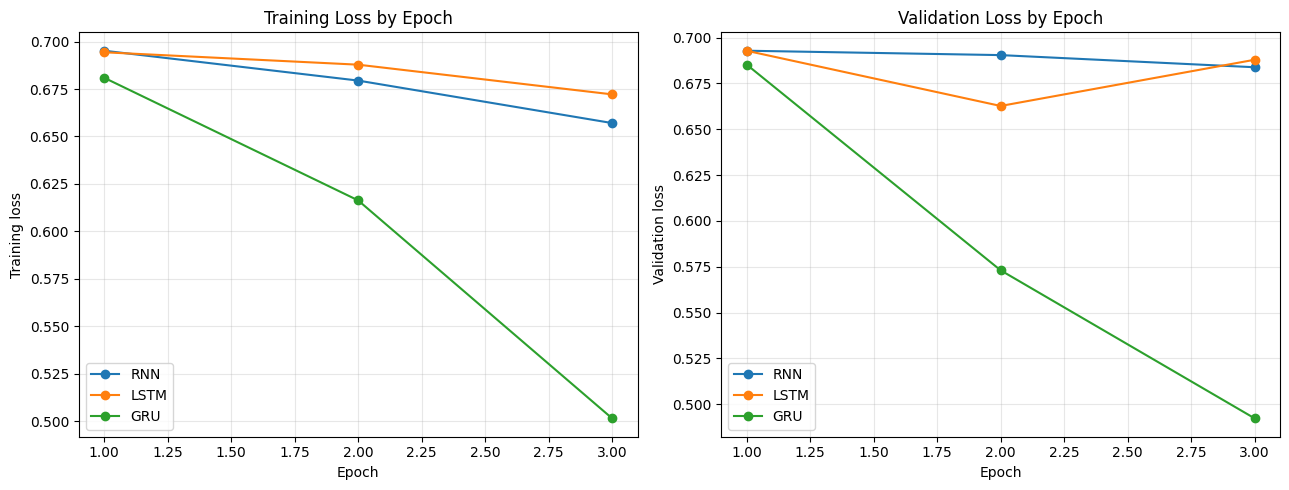

,Model,Best validation-loss epoch,Minimum validation loss,Final train loss,Final validation loss,Train loss decreased overall,Possible overfitting pattern (needs review)
0,RNN,3,0.683847,0.657072,0.683847,True,False
1,LSTM,2,0.662726,0.672196,0.687928,True,True
2,GRU,3,0.492328,0.501457,0.492328,True,False


Saved: /home/nguyenducthang/NLP/Lab5/learning_curves.png


In [47]:
# Gộp history đã lưu trong quá trình huấn luyện Experiment 4
learning_curve_frames = []
for model_name in ['RNN', 'LSTM', 'GRU']:
    model_history = exp4_histories[model_name].copy()
    model_history.insert(0, 'Model', model_name)
    learning_curve_frames.append(model_history)
learning_curve_table = pd.concat(learning_curve_frames, ignore_index=True)
display(learning_curve_table.style.format({
    'Train Loss': '{:.5f}', 'Validation Loss': '{:.5f}', 'Validation F1': '{:.4f}'
}))
learning_curve_table.to_csv(EVALUATION_RESULTS_DIR / 'learning_curve_values.csv', index=False)

curve_observations = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in ['RNN', 'LSTM', 'GRU']:
    history = exp4_histories[model_name].sort_values('Epoch')
    axes[0].plot(history['Epoch'], history['Train Loss'], marker='o', label=model_name)
    axes[1].plot(history['Epoch'], history['Validation Loss'], marker='o', label=model_name)
    best_val_row = history.loc[history['Validation Loss'].idxmin()]
    train_keeps_falling = bool(history['Train Loss'].iloc[-1] < history['Train Loss'].iloc[0])
    val_rises_after_min = bool(
        best_val_row.name != history.index[-1] and
        history.loc[best_val_row.name + 1:, 'Validation Loss'].gt(best_val_row['Validation Loss']).any()
    )
    curve_observations.append({
        'Model': model_name,
        'Best validation-loss epoch': int(best_val_row['Epoch']),
        'Minimum validation loss': float(best_val_row['Validation Loss']),
        'Final train loss': float(history['Train Loss'].iloc[-1]),
        'Final validation loss': float(history['Validation Loss'].iloc[-1]),
        'Train loss decreased overall': train_keeps_falling,
        'Possible overfitting pattern (needs review)': train_keeps_falling and val_rises_after_min
    })

axes[0].set(title='Training Loss by Epoch', xlabel='Epoch', ylabel='Training loss')
axes[1].set(title='Validation Loss by Epoch', xlabel='Epoch', ylabel='Validation loss')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
learning_curves_path = LAB_DIR / 'learning_curves.png'
fig.savefig(learning_curves_path, dpi=160)
plt.show()

curve_observation_table = pd.DataFrame(curve_observations)
display(curve_observation_table)
curve_observation_table.to_csv(EVALUATION_RESULTS_DIR / 'learning_curve_observations.csv', index=False)
print('Saved:', learning_curves_path)

# 24. Error Analysis

Chọn các ví dụ trực tiếp từ test split của IMDb bằng dự đoán LSTM. Các cờ dưới đây chỉ là dấu hiệu được phát hiện tự động, không xác nhận nguyên nhân.

## 24.1 Chọn và kiểm tra review thật từ test set

**Phân tích evidence-first (AI hỗ trợ):** Ba ví dụ đúng của LSTM gồm row 12500 (label 1, P+=0.5141; dài 142, cắt 42 token), row 2 (label 0, P+=0.3838; dài 134, cắt 34) và row 3 (label 0, P+=0.4294; dài 355, cắt 255). Ba ví dụ sai: row 0 là FP (0→1, P+=0.5215; dài 240, cắt 140), row 12505 là FN (1→0, P+=0.4610; dài 353, cắt 253), row 571 là FP (0→1, P+=0.7518; dài 156, cắt 56). Hai FP có cue phủ định/tương phản được phát hiện, còn row 571 có `but/though`; các cue chỉ là dấu hiệu để đọc review. Mức truncation lớn ở row 3 và 12505 là khả năng cần kiểm tra, nhưng chưa chứng minh phần bị cắt chứa bằng chứng quyết định. Các model khác không luôn đồng ý: row 0 GRU dự đoán đúng Negative trong khi RNN cũng sai Positive; row 12505 GRU đúng Positive còn RNN sai Negative.

**Chưa xác định nguyên nhân:** không thể kết luận các lỗi là do sequence modeling, truncation, negation hay nhãn mơ hồ chỉ từ các cờ tự động. Cần đọc toàn văn và phần 100 token model thực sự nhận, đối chiếu nhãn, rồi kiểm tra bằng controlled edits/so sánh model.

**Student verification:** tự chọn một hoặc nhiều case để phân tích ngữ nghĩa; trích đoạn văn bản làm evidence và ghi nguyên nhân như hypothesis cho đến khi được kiểm tra.

In [48]:
# Chạy dự đoán LSTM trên test set để giữ lại xác suất và logit theo đúng thứ tự
lstm_details, lstm_truth, lstm_predictions, lstm_probabilities, lstm_logits = evaluate_rnn(
    exp4_models['LSTM'], test_loader, DEVICE
)
if not np.array_equal(lstm_truth, y_test):
    raise ValueError('LSTM test predictions không cùng thứ tự với test_data')

correct_indices = np.flatnonzero(lstm_predictions == y_test)
wrong_indices = np.flatnonzero(lstm_predictions != y_test)
selected_correct = []
for label in [1, 0]:  # Ưu tiên một TP và một TN trước khi lấy thêm ví dụ đúng
    candidates = [i for i in correct_indices if y_test[i] == label]
    if candidates:
        selected_correct.append(int(candidates[0]))
for index in correct_indices:
    if len(selected_correct) >= 3:
        break
    if int(index) not in selected_correct:
        selected_correct.append(int(index))

# Ưu tiên lấy cả FP và FN; bổ sung lỗi có confidence cao nếu còn thiếu
selected_wrong = []
for label, prediction in [(0, 1), (1, 0)]:
    candidates = [i for i in wrong_indices if y_test[i] == label and lstm_predictions[i] == prediction]
    if candidates:
        selected_wrong.append(int(candidates[0]))
remaining_wrong = sorted(
    [int(i) for i in wrong_indices if int(i) not in selected_wrong],
    key=lambda i: abs(float(lstm_probabilities[i]) - 0.5), reverse=True
)
selected_wrong.extend(remaining_wrong[:max(0, 3 - len(selected_wrong))])
selected_indices = selected_correct[:3] + selected_wrong[:3]
if len(selected_correct) < 3 or len(selected_wrong) < 3:
    print('Cảnh báo: test predictions không có đủ 3 mẫu đúng và 3 mẫu sai.')

NEGATION_WORDS = {'not', 'no', 'never', 'hardly', 'neither', 'nor'}
CONTRAST_WORDS = {'but', 'however', 'although', 'though', 'despite', 'yet'}
error_rows = []
for index in selected_indices:
    text = str(test_data.iloc[index]['text'])
    tokens = tokenize(text)
    retained_tokens = tokens[:EXP4_CONFIG['max_length']]
    unk_count = sum(token not in vocab for token in retained_tokens)
    true_label = int(y_test[index])
    predicted_label = int(lstm_predictions[index])
    row = {
        'Test row index': index, 'Text': text,
        'True label': true_label, 'Predicted label': predicted_label,
        'P(positive)': float(lstm_probabilities[index]),
        'Correct': true_label == predicted_label,
        'Original sequence length': len(tokens),
        'Retained sequence length': min(len(tokens), EXP4_CONFIG['max_length']),
        'Truncated token count': max(0, len(tokens) - EXP4_CONFIG['max_length']),
        'Truncation percentage': (max(0, len(tokens) - EXP4_CONFIG['max_length']) / len(tokens) * 100) if tokens else 0.0,
        'UNK count': unk_count,
        'UNK percentage (retained)': (unk_count / len(retained_tokens) * 100) if retained_tokens else 0.0,
        'Negation keywords': ', '.join(sorted(set(tokens) & NEGATION_WORDS)),
        'Contrast keywords': ', '.join(sorted(set(tokens) & CONTRAST_WORDS)),
        'HTML/noise detected': bool(re.search(r'<[^>]+>|[^\x00-\x7F]', text)),
        'Very long review': len(tokens) > EXP4_CONFIG['max_length'],
        'Evidence': 'Detected features are cues for manual review only.',
        'Potential causes': 'Negation/context/contrast/truncation/vocabulary/noise; verify manually.',
        'Confirmed cause': 'Not established by automatic checks.',
        'Student interpretation': ''
    }
    for model_name in ['RNN', 'GRU']:
        row[f'{model_name} prediction'] = int(evaluation_predictions[model_name][index])
        row[f'{model_name} P(positive)'] = float(evaluate_rnn(
            exp4_models[model_name],
            DataLoader(TensorDataset(
                test_loader.dataset.tensors[0][index:index + 1],
                test_loader.dataset.tensors[1][index:index + 1],
                test_loader.dataset.tensors[2][index:index + 1]
            ), batch_size=1), DEVICE
        )[3][0])
    error_rows.append(row)

error_analysis_examples = pd.DataFrame(error_rows)
error_analysis_csv = EVALUATION_RESULTS_DIR / 'error_analysis_examples.csv'
error_analysis_examples.to_csv(error_analysis_csv, index=False)
display(error_analysis_examples.assign(Review=error_analysis_examples['Text'].str.slice(0, 350))[[
    'Test row index', 'Review', 'True label', 'Predicted label', 'P(positive)',
    'Correct', 'Original sequence length', 'Retained sequence length',
    'Truncated token count', 'UNK count', 'Negation keywords', 'Contrast keywords'
]])

# Tạo báo cáo evidence-first; không khẳng định nguyên nhân và để diễn giải cho sinh viên
report_lines = [
    '# Error Analysis — LSTM test examples', '',
    'Nguồn: IMDb test split; chọn mẫu theo prediction LSTM. Labels: 0=Negative, 1=Positive.',
    'Automated flags are detected features, not confirmed causes.', ''
]
for _, row in error_analysis_examples.iterrows():
    report_lines.extend([
        f"## Test row {int(row['Test row index'])} — {'Correct' if row['Correct'] else 'Incorrect'}", '',
        f"- Ground truth: {int(row['True label'])}",
        f"- LSTM prediction: {int(row['Predicted label'])}",
        f"- P(positive): {row['P(positive)']:.6f}",
        f"- Sequence length: {int(row['Original sequence length'])}; retained: {int(row['Retained sequence length'])}",
        f"- Truncation: {int(row['Truncated token count'])} tokens ({row['Truncation percentage']:.2f}%)",
        f"- UNK: {int(row['UNK count'])} ({row['UNK percentage (retained)']:.2f}% of retained tokens)",
        f"- Negation cues: {row['Negation keywords'] or 'none detected'}",
        f"- Contrast cues: {row['Contrast keywords'] or 'none detected'}",
        f"- RNN prediction / P(+): {row['RNN prediction']} / {row['RNN P(positive)']:.6f}",
        f"- GRU prediction / P(+): {row['GRU prediction']} / {row['GRU P(positive)']:.6f}",
        '- Review (excerpt):', '', f"> {str(row['Text'])[:1200]}", '',
        '- Evidence:', '  - Use the measurable fields above; inspect the full text in the CSV.',
        '- Potential causes: manual hypotheses only; verify against the review text and input.',
        '- Is this error caused by sequence modeling? What additional evidence is needed?',
        '- Student interpretation: [write your own analysis]', ''
    ])
(LAB_DIR / 'error_analysis.md').write_text('\n'.join(report_lines), encoding='utf-8')
print('Saved:', error_analysis_csv, LAB_DIR / 'error_analysis.md')

,Test row index,Review,True label,Predicted label,P(positive),Correct,Original sequence length,Retained sequence length,Truncated token count,UNK count,Negation keywords,Contrast keywords
0,12500,Previous reviewer Claudio Carvalho gave a much...,1,1,0.514119,True,142,100,42,3,,but
1,2,its a totally average film with a few semi-alr...,0,0,0.383809,True,134,100,34,2,not,though
2,3,STAR RATING: ***** Saturday Night **** Friday ...,0,0,0.429366,True,355,100,255,5,"never, no",but
3,0,I love sci-fi and am willing to put up with a ...,0,1,0.521517,False,240,100,140,2,not,"but, yet"
4,12505,"Overall, a well done movie. There were the par...",1,0,0.461034,False,353,100,253,2,not,but
5,571,Dorothy Provine does the opposite here: She ke...,0,1,0.751837,False,156,100,56,4,,"but, though"


Saved: /home/nguyenducthang/NLP/Lab5/results/error_analysis_examples.csv /home/nguyenducthang/NLP/Lab5/error_analysis.md


## Report note

Các bảng/ảnh được tạo trực tiếp từ kết quả thực thi. Câu hỏi diễn giải cá nhân và khẳng định nguyên nhân trong error analysis được để cho sinh viên tự kiểm chứng.

# 26. Application — Sentiment Classifier

Dùng lại LSTM và GRU checkpoint từ Experiment 4; không huấn luyện lại. Pipeline: review → tokenizer/vocabulary → IDs → truncation/padding → embedding → recurrent layer → linear → xác suất sentiment.

## 26.1 Pipeline, model và các review kiểm thử

In [10]:
# Chỉ nạp checkpoint đã huấn luyện và xác minh vocabulary tương thích
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
APPLICATION_CHECKPOINT_DIR = LAB_DIR / 'models' / 'rnn_lstm_gru'
application_models = {}
for model_type in ['LSTM', 'GRU']:
    checkpoint_path = APPLICATION_CHECKPOINT_DIR / f'{model_type.lower()}_best.pt'
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy checkpoint đã train: {checkpoint_path}')
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    if checkpoint.get('vocab_size') != len(vocab):
        raise ValueError(f'Vocabulary không khớp checkpoint {model_type}')
    config = checkpoint['config']
    model = RecurrentSentimentClassifier(
        vocab_size=len(vocab), embedding_dim=config['embedding_dim'],
        hidden_size=config['hidden_size'], model_type=model_type,
        num_layers=config['num_layers'], dropout=config['dropout']
    ).to(DEVICE)
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    application_models[model_type] = {
        'model': model, 'max_length': int(config['max_length'])
    }

def application_predict_tokens(tokens, model, max_length):
    # Chuyển tokens thành IDs, rồi dùng cùng truncation và padding của quá trình train
    token_ids = [vocab.get(token, UNK_ID) for token in tokens]
    full_length = len(token_ids)
    retained_ids = token_ids[:max_length]
    retained_tokens = tokens[:max_length]
    if not retained_ids:
        retained_ids = [UNK_ID]
        retained_tokens = [UNK_TOKEN]
    sequence_length = len(retained_ids)
    padded_ids = retained_ids + [PAD_ID] * (max_length - sequence_length)
    ids_tensor = torch.tensor([padded_ids], dtype=torch.long, device=DEVICE)
    lengths_tensor = torch.tensor([sequence_length], dtype=torch.long, device=DEVICE)
    model.eval()
    with torch.no_grad():
        logit = model(ids_tensor, lengths_tensor)
        probability = float(torch.sigmoid(logit).item())
    return {
        'Prediction': 'Positive' if probability >= 0.5 else 'Negative',
        'P(positive)': probability, 'Original tokens': full_length,
        'Retained tokens': min(full_length, max_length),
        'Truncated tokens': max(0, full_length - max_length),
        'UNK in retained input': sum(token not in vocab for token in retained_tokens),
        'Retained token list': retained_tokens
    }

def application_predict(text, model_name):
    # Dự đoán một review bằng model đã nạp ở trên
    tokens = tokenize(text)
    model_info = application_models[model_name]
    return application_predict_tokens(
        tokens, model_info['model'], model_info['max_length']
    )

def remove_phrase_tokens(tokens, phrase):
    # Loại toàn bộ lần xuất hiện liên tiếp của phrase khỏi token list
    phrase_tokens = tokenize(phrase)
    if not phrase_tokens:
        return list(tokens)
    result, index = [], 0
    while index < len(tokens):
        if tokens[index:index + len(phrase_tokens)] == phrase_tokens:
            index += len(phrase_tokens)
        else:
            result.append(tokens[index])
            index += 1
    return result

def compare_application_variants(review_name, base_tokens, variants):
    # Chạy các biến thể trên LSTM và GRU, rồi ghi delta so với câu gốc cùng model
    rows = []
    for model_name in application_models:
        base = application_predict_tokens(
            base_tokens, application_models[model_name]['model'],
            application_models[model_name]['max_length']
        )
        for variant_name, variant_tokens in [('Original', base_tokens), *variants]:
            result = application_predict_tokens(
                variant_tokens, application_models[model_name]['model'],
                application_models[model_name]['max_length']
            )
            rows.append({
                'Review type': review_name, 'Model': model_name,
                'Variant': variant_name, 'Prediction': result['Prediction'],
                'P(positive)': result['P(positive)'],
                'Delta vs original': result['P(positive)'] - base['P(positive)'],
                'Original tokens': result['Original tokens'],
                'Retained tokens': result['Retained tokens'],
                'Truncated tokens': result['Truncated tokens']
            })
    return pd.DataFrame(rows)

print('Models loaded:', list(application_models))
print('Vocabulary size:', len(vocab), '| PAD_ID:', PAD_ID, '| UNK_ID:', UNK_ID)
print('Device:', DEVICE, '| max_length:', {k: v['max_length'] for k, v in application_models.items()})

Models loaded: ['LSTM', 'GRU']
Vocabulary size: 20000 | PAD_ID: 0 | UNK_ID: 1
Device: cpu | max_length: {'LSTM': 100, 'GRU': 100}


### 26.2 Short Review

In [11]:
short_review = 'I enjoyed this movie. The acting was excellent and the story was touching.'
short_tokens = tokenize(short_review)
short_variants = [('Without "enjoyed"', remove_phrase_tokens(short_tokens, 'enjoyed'))]
short_results = compare_application_variants('Short', short_tokens, short_variants)
display(short_results.style.format({'P(positive)': '{:.4f}', 'Delta vs original': '{:+.4f}'}))
short_results.to_csv(LAB_DIR / 'results' / 'application_short_results.csv', index=False)
print('Review:', short_review)

,Review type,Model,Variant,Prediction,P(positive),Delta vs original,Original tokens,Retained tokens,Truncated tokens
0,Short,LSTM,Original,Negative,0.4720,+0.0000,13,13,0
1,Short,LSTM,"Without ""enjoyed""",Negative,0.4766,+0.0046,12,12,0
2,Short,GRU,Original,Positive,0.5867,+0.0000,13,13,0
3,Short,GRU,"Without ""enjoyed""",Positive,0.5417,-0.0450,12,12,0


Review: I enjoyed this movie. The acting was excellent and the story was touching.


**Nhận xét thực nghiệm:** Review ngắn có 13 token; LSTM dự đoán Negative với P(positive)=0.4720. Khi bỏ `enjoyed`, P(positive)=0.4766 (delta +0.0046); đây là thay đổi quan sát được trong phép occlusion, không khẳng định riêng từ đó gây ra toàn bộ dự đoán.

### 26.3 Long Review

In [12]:
long_review = (
    'I went into this film with high expectations because the director had made several thoughtful dramas before. '
    'The opening scene was beautiful, and the lead actors seemed completely believable. For a while the story moved '
    'at a comfortable pace, with small details that made the characters feel real. The soundtrack was subtle, the '
    'camera work was impressive, and a few early conversations were surprisingly good. However, the second act '
    'repeated the same conflict several times, and the supporting characters were not developed enough to make their '
    'choices convincing. Some jokes fell flat, some scenes felt unnecessarily long, and the editing made the middle '
    'section drag. I kept hoping the final act would bring the separate storylines together. Near the end, one '
    'performance became excellent and the conclusion was more moving than I expected. I enjoyed parts of the film, '
    'but overall it was uneven and too slow to recommend without reservations.'
)
long_tokens = tokenize(long_review)
long_max_length = application_models['LSTM']['max_length']
long_retained = long_tokens[:long_max_length]
long_rows = []
for model_name in application_models:
    prediction = application_predict(long_review, model_name)
    long_rows.append({
        'Model': model_name, 'Prediction': prediction['Prediction'],
        'P(positive)': prediction['P(positive)'],
        'Original tokens': prediction['Original tokens'],
        'Retained tokens': prediction['Retained tokens'],
        'Truncated tokens': prediction['Truncated tokens'],
        'UNK in retained input': prediction['UNK in retained input']
    })
long_results = pd.DataFrame(long_rows)
display(long_results.style.format({'P(positive)': '{:.4f}'}))

sentiment_cues = {'excellent', 'beautiful', 'believable', 'impressive', 'good', 'moving',
                  'enjoyed', 'recommend', 'uneven', 'slow', 'boring', 'terrible', 'not'}
long_cue_rows = [
    {'Token': token, 'Index': index, 'In model input': index < long_max_length}
    for index, token in enumerate(long_tokens) if token in sentiment_cues
]
long_cue_table = pd.DataFrame(long_cue_rows)
display(long_cue_table)
long_results.to_csv(LAB_DIR / 'results' / 'application_long_results.csv', index=False)
long_cue_table.to_csv(LAB_DIR / 'results' / 'application_long_keyword_positions.csv', index=False)
long_variant = remove_phrase_tokens(long_retained, 'surprisingly good')
long_occlusion = compare_application_variants(
    'Long', long_retained, [('Without "surprisingly good"', long_variant)]
)
display(long_occlusion.style.format({'P(positive)': '{:.4f}', 'Delta vs original': '{:+.4f}'}))
long_occlusion.to_csv(LAB_DIR / 'results' / 'application_long_occlusion.csv', index=False)
print('Retained input tokens:', ' '.join(long_retained))

,Model,Prediction,P(positive),Original tokens,Retained tokens,Truncated tokens,UNK in retained input
0,LSTM,Negative,0.4900,151,100,51,0
1,GRU,Positive,0.6625,151,100,51,0


,Token,Index,In model input
0,beautiful,21,True
1,believable,28,True
2,impressive,56,True
3,good,64,True
4,not,80,True
5,excellent,123,False
6,moving,129,False
7,enjoyed,134,False
8,uneven,143,False
9,slow,146,False


,Review type,Model,Variant,Prediction,P(positive),Delta vs original,Original tokens,Retained tokens,Truncated tokens
0,Long,LSTM,Original,Negative,0.4900,+0.0000,100,100,0
1,Long,LSTM,"Without ""surprisingly good""",Negative,0.4899,-0.0001,98,98,0
2,Long,GRU,Original,Positive,0.6625,+0.0000,100,100,0
3,Long,GRU,"Without ""surprisingly good""",Positive,0.6594,-0.0031,98,98,0


Retained input tokens: i went into this film with high expectations because the director had made several thoughtful dramas before the opening scene was beautiful and the lead actors seemed completely believable for a while the story moved at a comfortable pace with small details that made the characters feel real the soundtrack was subtle the camera work was impressive and a few early conversations were surprisingly good however the second act repeated the same conflict several times and the supporting characters were not developed enough to make their choices convincing some jokes fell flat some scenes felt unnecessarily long and the editing


**Nhận xét thực nghiệm:** Review dài có 151 token; LSTM chỉ nhận 100 và 51 token bị cắt. P(positive) gốc là 0.4900; các cue còn trong input gồm beautiful, believable, impressive, good, not. Bỏ `surprisingly good` đổi P(positive) thành 0.4899 (delta -0.0001); `excellent` nằm ngoài input được giữ.

### 26.4 Negation Review

In [13]:
negation_review = 'The plot is not interesting, the acting is not convincing, and I would not recommend this movie.'
negation_tokens = tokenize(negation_review)
without_not = remove_phrase_tokens(negation_tokens, 'not')
negation_results = compare_application_variants(
    'Negation', negation_tokens, [('Without all "not" tokens', without_not)]
)
display(negation_results.style.format({'P(positive)': '{:.4f}', 'Delta vs original': '{:+.4f}'}))
negation_results.to_csv(LAB_DIR / 'results' / 'application_negation_results.csv', index=False)
print('Original:', negation_review)
print('After removing "not":', ' '.join(without_not))

,Review type,Model,Variant,Prediction,P(positive),Delta vs original,Original tokens,Retained tokens,Truncated tokens
0,Negation,LSTM,Original,Negative,0.3538,+0.0000,17,17,0
1,Negation,LSTM,"Without all ""not"" tokens",Negative,0.3982,+0.0444,14,14,0
2,Negation,GRU,Original,Negative,0.2988,+0.0000,17,17,0
3,Negation,GRU,"Without all ""not"" tokens",Positive,0.5092,+0.2104,14,14,0


Original: The plot is not interesting, the acting is not convincing, and I would not recommend this movie.
After removing "not": the plot is interesting the acting is convincing and i would recommend this movie


**Nhận xét thực nghiệm:** LSTM dự đoán câu gốc là Negative với P(positive)=0.3538. Sau khi xóa cả ba token `not`, dự đoán là Negative và P(positive)=0.3982 (delta +0.0444); đây là phép can thiệp lên câu, không phải kiểm tra mọi cách dùng phủ định.

### 26.5 Contrast Review

In [14]:
contrast_review = (
    'The script is terrible and the first half is slow, but surprisingly good performances '
    'and a moving ending make the movie enjoyable.'
)
contrast_tokens = tokenize(contrast_review)
contrast_variants = [
    ('Without "terrible"', remove_phrase_tokens(contrast_tokens, 'terrible')),
    ('Without "but"', remove_phrase_tokens(contrast_tokens, 'but')),
    ('Without "surprisingly good"', remove_phrase_tokens(contrast_tokens, 'surprisingly good'))
]
contrast_results = compare_application_variants('Contrast', contrast_tokens, contrast_variants)
display(contrast_results.style.format({'P(positive)': '{:.4f}', 'Delta vs original': '{:+.4f}'}))
contrast_results.to_csv(LAB_DIR / 'results' / 'application_contrast_results.csv', index=False)
print('Review:', contrast_review)

,Review type,Model,Variant,Prediction,P(positive),Delta vs original,Original tokens,Retained tokens,Truncated tokens
0,Contrast,LSTM,Original,Positive,0.5204,+0.0000,22,22,0
1,Contrast,LSTM,"Without ""terrible""",Positive,0.5270,+0.0066,21,21,0
2,Contrast,LSTM,"Without ""but""",Positive,0.5007,-0.0197,21,21,0
3,Contrast,LSTM,"Without ""surprisingly good""",Positive,0.5017,-0.0186,20,20,0
4,Contrast,GRU,Original,Negative,0.3778,+0.0000,22,22,0
5,Contrast,GRU,"Without ""terrible""",Positive,0.6189,+0.2411,21,21,0
6,Contrast,GRU,"Without ""but""",Negative,0.3935,+0.0157,21,21,0
7,Contrast,GRU,"Without ""surprisingly good""",Negative,0.4089,+0.0310,20,20,0


Review: The script is terrible and the first half is slow, but surprisingly good performances and a moving ending make the movie enjoyable.


**Nhận xét thực nghiệm:** Câu gốc có P(positive)=0.5204 và nhãn Positive. Trong ba phép xóa, ` Without "but" ` làm thay đổi tuyệt đối lớn nhất: P(positive)=0.5007, delta -0.0197. Without "terrible": +0.0066; Without "but": -0.0197; Without "surprisingly good": -0.0186. Đây là độ nhạy với các biến thể cụ thể, không chứng minh mô hình xử lý đúng cấu trúc tương phản.

### 26.6 Keyword Analysis và Occlusion Analysis


Short: top token occlusions by absolute probability change


,Index,Token,Context,Base P(positive),Occluded P(positive),Delta P(positive),Absolute delta
11,11,was,excellent and the story [was] touching,0.4720,0.5176,+0.0456,0.0456
7,7,excellent,movie the acting was [excellent] and the story was,0.4720,0.4463,-0.0257,0.0257
8,8,and,the acting was excellent [and] the story was touching,0.4720,0.4480,-0.0240,0.0240
3,3,movie,i enjoyed this [movie] the acting was excellent,0.4720,0.4932,+0.0212,0.0212
10,10,story,was excellent and the [story] was touching,0.4720,0.4532,-0.0188,0.0188
2,2,this,i enjoyed [this] movie the acting was,0.4720,0.4900,+0.0180,0.0180
9,9,the,acting was excellent and [the] story was touching,0.4720,0.4889,+0.0168,0.0168
6,6,was,this movie the acting [was] excellent and the story,0.4720,0.4811,+0.0091,0.0091



Long: top token occlusions by absolute probability change


,Index,Token,Context,Base P(positive),Occluded P(positive),Delta P(positive),Absolute delta
97,97,and,scenes felt unnecessarily long [and] the editing,0.4900,0.4503,-0.0398,0.0398
98,98,the,felt unnecessarily long and [the] editing,0.4900,0.5125,+0.0225,0.0225
94,94,felt,fell flat some scenes [felt] unnecessarily long and the,0.4900,0.4755,-0.0146,0.0146
90,90,fell,choices convincing some jokes [fell] flat some scenes felt,0.4900,0.5035,+0.0135,0.0135
95,95,unnecessarily,flat some scenes felt [unnecessarily] long and the editing,0.4900,0.5005,+0.0104,0.0104
83,83,to,were not developed enough [to] make their choices convincing,0.4900,0.4994,+0.0094,0.0094
85,85,their,developed enough to make [their] choices convincing some jokes,0.4900,0.4818,-0.0082,0.0082
92,92,some,some jokes fell flat [some] scenes felt unnecessarily long,0.4900,0.4977,+0.0076,0.0076



Negation: top token occlusions by absolute probability change


,Index,Token,Context,Base P(positive),Occluded P(positive),Delta P(positive),Absolute delta
15,15,this,i would not recommend [this] movie,0.3538,0.4080,+0.0541,0.0541
13,13,not,convincing and i would [not] recommend this movie,0.3538,0.3699,+0.0160,0.0160
16,16,movie,would not recommend this [movie],0.3538,0.3652,+0.0114,0.0114
10,10,and,acting is not convincing [and] i would not recommend,0.3538,0.3434,-0.0104,0.0104
0,0,the,[the] plot is not interesting,0.3538,0.3622,+0.0084,0.0084
8,8,not,interesting the acting is [not] convincing and i would,0.3538,0.3617,+0.0079,0.0079
1,1,plot,the [plot] is not interesting the,0.3538,0.3614,+0.0076,0.0076
5,5,the,plot is not interesting [the] acting is not convincing,0.3538,0.3610,+0.0072,0.0072



Contrast: top token occlusions by absolute probability change


,Index,Token,Context,Base P(positive),Occluded P(positive),Delta P(positive),Absolute delta
14,14,and,but surprisingly good performances [and] a moving ending make,0.5204,0.4497,-0.0706,0.0706
13,13,performances,slow but surprisingly good [performances] and a moving ending,0.5204,0.4553,-0.0651,0.0651
6,6,first,is terrible and the [first] half is slow but,0.5204,0.5830,+0.0627,0.0627
20,20,movie,moving ending make the [movie] enjoyable,0.5204,0.5768,+0.0565,0.0565
0,0,the,[the] script is terrible and,0.5204,0.5692,+0.0489,0.0489
9,9,slow,the first half is [slow] but surprisingly good performances,0.5204,0.4799,-0.0405,0.0405
5,5,the,script is terrible and [the] first half is slow,0.5204,0.5584,+0.0381,0.0381
17,17,ending,performances and a moving [ending] make the movie enjoyable,0.5204,0.4835,-0.0369,0.0369


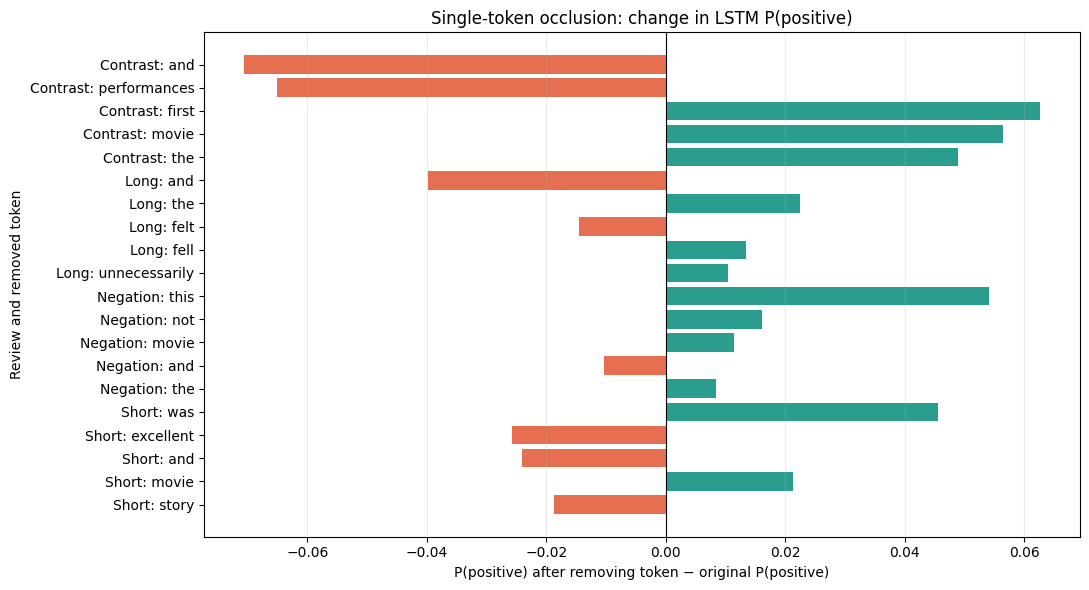

Saved: /home/nguyenducthang/NLP/Lab5/results/application_keyword_occlusion.csv /home/nguyenducthang/NLP/Lab5/figures/application_occlusion.png


In [15]:
def single_token_occlusion(tokens, model_name):
    # Bỏ từng token trong phần model thực sự nhận, giữ nguyên giới hạn sequence
    model_info = application_models[model_name]
    kept = tokens[:model_info['max_length']]
    base = application_predict_tokens(kept, model_info['model'], model_info['max_length'])
    rows = []
    for index, token in enumerate(kept):
        changed = kept[:index] + kept[index + 1:]
        result = application_predict_tokens(changed, model_info['model'], model_info['max_length'])
        left = ' '.join(kept[max(0, index - 4):index])
        right = ' '.join(kept[index + 1:index + 5])
        rows.append({
            'Index': index, 'Token': token, 'Context': f'{left} [{token}] {right}'.strip(),
            'Base P(positive)': base['P(positive)'],
            'Occluded P(positive)': result['P(positive)'],
            'Delta P(positive)': result['P(positive)'] - base['P(positive)'],
            'Absolute delta': abs(result['P(positive)'] - base['P(positive)'])
        })
    return pd.DataFrame(rows)

application_reviews = {
    'Short': short_tokens, 'Long': long_tokens,
    'Negation': negation_tokens, 'Contrast': contrast_tokens
}
keyword_occlusion_tables = {}
for review_name, review_tokens in application_reviews.items():
    table = single_token_occlusion(review_tokens, 'LSTM')
    keyword_occlusion_tables[review_name] = table
    print(f'\n{review_name}: top token occlusions by absolute probability change')
    display(table.sort_values('Absolute delta', ascending=False).head(8).style.format({
        'Base P(positive)': '{:.4f}', 'Occluded P(positive)': '{:.4f}',
        'Delta P(positive)': '{:+.4f}', 'Absolute delta': '{:.4f}'
    }))

all_keyword_occlusions = pd.concat(
    [table.assign(**{'Review type': name}) for name, table in keyword_occlusion_tables.items()],
    ignore_index=True
)
all_keyword_occlusions.to_csv(LAB_DIR / 'results' / 'application_keyword_occlusion.csv', index=False)

# Vẽ các token có độ đổi xác suất tuyệt đối lớn nhất ở từng review
top_occlusions = all_keyword_occlusions.sort_values(
    ['Review type', 'Absolute delta'], ascending=[True, False]
).groupby('Review type', sort=False).head(5).copy()
top_occlusions['Label'] = top_occlusions['Review type'] + ': ' + top_occlusions['Token']
fig, ax = plt.subplots(figsize=(11, 6))
colors = ['#2a9d8f' if value >= 0 else '#e76f51' for value in top_occlusions['Delta P(positive)']]
ax.barh(top_occlusions['Label'][::-1], top_occlusions['Delta P(positive)'][::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Single-token occlusion: change in LSTM P(positive)',
       xlabel='P(positive) after removing token − original P(positive)', ylabel='Review and removed token')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
application_plot_path = LAB_DIR / 'figures' / 'application_occlusion.png'
fig.savefig(application_plot_path, dpi=160)
plt.show()
print('Saved:', LAB_DIR / 'results' / 'application_keyword_occlusion.csv', application_plot_path)

### 26.7 Question & Experimental Analysis — phân tích tham khảo (AI hỗ trợ)

**Question: Những từ hoặc đoạn context nào có khả năng ảnh hưởng tới prediction?**

Trong các phép occlusion đã chạy, xóa `not` khỏi câu phủ định làm P(positive) của GRU tăng 0.2104 và đổi Negative thành Positive; với LSTM tăng 0.0444 nhưng vẫn Negative. Xóa `terrible` khỏi câu tương phản làm P(positive) GRU tăng 0.2411 và đổi Negative thành Positive; xóa `but` đổi P(positive) GRU +0.0157, LSTM -0.0197. Xóa `surprisingly good` đổi GRU +0.0310 và LSTM -0.0186. Ở short review, bỏ `enjoyed` đổi P(positive) LSTM +0.0046 và GRU -0.0450. Đây là bằng chứng output nhạy với các chỉnh sửa cụ thể, không xác nhận từ/cụm đó là nguyên nhân duy nhất hay mô hình hiểu ngữ nghĩa.

Ở long review, 151 token chỉ còn 100 token đầu được đưa vào; 51 token cuối bị cắt. Vì vậy `excellent`, `moving`, `enjoyed`, `uneven`, `slow` và `recommend` ở phần sau không nằm trong input của lượt dự đoán này. LSTM dự đoán Negative (P+=0.4900), GRU Positive (0.6625).

**Student verification:** để kết luận về ảnh hưởng của từ/context cần kiểm tra câu gốc và biến thể, giữ các yếu tố khác ổn định, thử nhiều câu và mô hình; một lần xóa token có thể làm thay đổi cả cấu trúc câu. Không trình bày phân tích AI này như trải nghiệm cá nhân của sinh viên.